# 01 · Inventario, etiquetas y vista general de las 10 señales

**Capítulo 1 — Etapas 0 y 1 del pipeline · Bloques A (integridad) y J (autorreporte) del EDA**

## ¿Qué hace este notebook?
Antes de limpiar nada, revisamos **qué hay en los datos**:
1. ¿Están completos todos los sujetos y todas las señales? ¿Duran lo mismo el pecho y la muñeca?
2. ¿Cuánto tiempo hay de cada condición (línea base, estrés, diversión, meditación)?
3. ¿Cómo se ven las 10 señales durante toda la sesión?
4. ¿Los valores de cada señal están en rangos fisiológicos? (distribución por condición)
5. ¿Los participantes **reportaron** sentirse estresados en el estrés? (cuestionarios)

Aquí se analizan **las 10 señales**. La limpieza (notebook 03) solo se aplica a las señales importantes.

## Antes de empezar
- La carpeta `WESAD/` debe estar al lado de esta carpeta (`../WESAD`). Si está en otro lugar, cambia `DATA_PATH` abajo.
- La carpeta `wesad_pre/` (el código del pipeline) debe estar junto a este notebook.
- Dato importante: **los `.pkl` de WESAD ya vienen en unidades físicas** (mV, µS, °C, %). Por eso aquí no se convierte nada, a diferencia del notebook 02 anterior.

> **Glosario rápido**
> - **Señal**: una serie de números en el tiempo (p. ej. el ECG son 700 números por segundo).
> - **fs (frecuencia de muestreo)**: cuántos números por segundo tiene la señal.
> - **Condición**: lo que el participante estaba viviendo (línea base, estrés, diversión, meditación).
> - **Bloque**: un tramo continuo de una condición.
> - **QC (control de calidad)**: revisar qué muestras son confiables.

## 0. Preparación
Si es la primera vez, instala las librerías (quita el `#` de la siguiente celda y ejecútala una sola vez).

In [1]:
# %pip install neurokit2 cvxopt seaborn

In [2]:
import os, gc, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from wesad_pre import config as cfg
from wesad_pre import carga, etiquetas, calidad, limpieza, eventos, procesamiento, marcadores, estadistica, ventanas
from wesad_pre import graficas as gr

warnings.filterwarnings("ignore")
gr.setup()
pd.set_option("display.max_columns", 50, "display.width", 200)

DATA_PATH = os.path.join("..", "WESAD")   # carpeta con S2/, S3/, ... (ajústala si los datos están en otro lugar)
SUBJECTS = cfg.SUBJECT_IDS
os.makedirs(cfg.OUT_DIRS["tables"], exist_ok=True)

### Las señales y su papel en el proyecto
Esta tabla resume qué señal es cuál, a qué frecuencia viene y **qué rol cumple**:
- **nucleo** → ECG, EDA y respiración de pecho: se limpian y entran al modelo base (objetivo 2).
- **apoyo** → temperatura de pecho: *apoyo a considerar*. Se limpia, se revisa su calidad y se exporta en las
  ventanas, pero no entra al modelo base; el objetivo 2 decide si se agrega como complemento.
- **movimiento** → los acelerómetros; no predicen estrés, sirven para detectar artefactos.
- **exploratoria** → EMG; solo se analiza en el EDA.

In [3]:
pd.DataFrame(cfg.SIGNALS).T[["name", "device", "fs", "unit", "role"]].rename(
    columns={"name": "señal", "device": "dispositivo", "fs": "fs (Hz)", "unit": "unidad", "role": "rol"})

,señal,dispositivo,fs (Hz),unidad,rol
chest_ECG,ECG (pecho),chest,700,mV,nucleo
chest_EDA,EDA (pecho),chest,700,µS,nucleo
chest_Resp,Respiración (pecho),chest,700,%,nucleo
wrist_BVP,BVP (muñeca),wrist,64,u.a.,exploratoria
wrist_EDA,EDA (muñeca),wrist,4,µS,exploratoria
chest_Temp,Temperatura (pecho),chest,700,°C,apoyo
wrist_TEMP,Temperatura (muñeca),wrist,4,°C,exploratoria
chest_ACC,Acelerómetro (pecho),chest,700,g,movimiento
wrist_ACC,Acelerómetro (muñeca),wrist,32,g,movimiento
chest_EMG,EMG (pecho),chest,700,mV,exploratoria


## 1. Inventario: ¿están completos los datos?
Para cada sujeto calculamos la duración de cada señal (número de muestras ÷ fs). Si todo está bien sincronizado,
**todas las señales de un sujeto deben durar lo mismo** que las etiquetas. La columna `desfase_max_s` muestra la
mayor diferencia (en segundos) entre señales del mismo sujeto. Valores de unos pocos segundos o menos son normales.

También leemos del `SX_readme.txt` los datos del participante y las **notas del investigador**, que pueden explicar
comportamientos raros más adelante (p. ej. un sensor mal puesto).

In [4]:
inv_rows, notas = [], {}
for sid in SUBJECTS:
    data = carga.load_subject(DATA_PATH, sid)
    dur_label = len(data["label"]) / cfg.FS_LABEL
    row = {"sujeto": f"S{sid}", "duracion_etiquetas_min": dur_label / 60}
    durs = {}
    for key, spec in cfg.SIGNALS.items():
        x = carga.get_signal(data, key)
        durs[key] = len(x) / spec["fs"]
        row[f"nan__{key}"] = int((~np.isfinite(x)).sum())
    row["desfase_max_s"] = max(abs(d - dur_label) for d in durs.values())
    info = carga.read_info(DATA_PATH, sid)
    row.update(edad=info.get("Age"), sexo=info.get("Gender"), mano_dominante=info.get("Dominant hand"),
               cafe_hoy=info.get("Did you drink coffee today?"), deporte_hoy=info.get("Did you do any sports today?"),
               fumador=info.get("Are you a smoker?"))
    inv_rows.append(row)
    notas[f"S{sid}"] = carga.read_notes(DATA_PATH, sid)
    del data; _ = gc.collect()

inventario = pd.DataFrame(inv_rows)
nan_cols = [c for c in inventario if c.startswith("nan__")]
inventario["nan_total"] = inventario[nan_cols].sum(axis=1)
inventario.drop(columns=nan_cols).round(2)

,sujeto,duracion_etiquetas_min,desfase_max_s,edad,sexo,mano_dominante,cafe_hoy,deporte_hoy,fumador,nan_total
0,S2,101.32,0.0,27,male,right,NO,NO,NO,0
1,S3,108.22,0.0,27,male,right,NO,NO,NO,0
2,S4,107.05,0.0,25,male,right,NO,NO,NO,0
3,S5,104.30,0.0,35,male,right,YES,NO,NO,0
4,S6,117.85,0.0,27,male,right,YES,NO,YES,0
5,S7,87.30,0.0,28,male,right,NO,YES,NO,0
6,S8,91.10,0.0,27,female,left,YES,YES,NO,0
7,S9,87.05,0.0,26,male,right,NO,NO,NO,0
8,S10,91.60,0.0,28,male,right,NO,NO,NO,0
9,S11,87.22,0.0,26,female,right,YES,NO,NO,0


**Notas del investigador** (del `SX_readme.txt`). Las tendremos presentes al interpretar resultados:

In [5]:
notas_df = pd.DataFrame({"sujeto": list(notas), "nota": list(notas.values())})
notas_df[notas_df.nota != ""]

,sujeto,nota
0,S2,The RespiBAN temperature sensor was not fully ...
1,S3,"During the baseline condition, the subject was..."
3,S5,Subject might have fallen asleep during the fi...
4,S6,Subject claimed that he had a stressfull week ...
6,S8,"Subject had already a rather stressful day, pr..."
12,S15,Subject didn't really believe the cover story ...
13,S16,Subject felt rather cold in the room where the...
14,S17,The RespiBAN temperature sensor was not fully ...


## 2. Condiciones del protocolo: ¿cuánto tiempo hay de cada una?
Las etiquetas de WESAD vienen a 700 Hz. Las agrupamos en **bloques continuos** por condición.
La meditación aparece dos veces en el protocolo (bloques 1 y 2).

In [6]:
bloques = []
for sid in SUBJECTS:
    data = carga.load_subject(DATA_PATH, sid)
    b = etiquetas.condition_blocks(data["label"])
    b.insert(0, "sujeto", f"S{sid}")
    bloques.append(b)
    del data; _ = gc.collect()
bloques = pd.concat(bloques, ignore_index=True)
bloques.to_csv(os.path.join(cfg.OUT_DIRS["tables"], "bloques_condicion.csv"), index=False)

minutos = bloques.pivot_table(index="sujeto", columns="condicion", values="duracion_s", aggfunc="sum") / 60
minutos = minutos[cfg.COND_ORDER].loc[sorted(minutos.index, key=gr.subject_sort_key)]
minutos.loc["promedio"] = minutos.mean()
minutos.round(1)

condicion,baseline,stress,amusement,meditation
sujeto,,,,
S2,19.1,10.2,6.0,12.8
S3,19.0,10.7,6.2,13.0
S4,19.3,10.6,6.2,13.4
S5,20.0,10.8,6.2,13.2
S6,19.7,10.8,6.2,13.1
S7,19.8,10.7,6.2,13.2
S8,19.5,11.2,6.2,13.3
S9,19.7,10.8,6.2,13.2
S10,19.7,12.1,6.2,13.3


**Cómo leer la figura siguiente:** cada fila es un sujeto y cada barra de color es un bloque de condición en el
momento en que ocurrió. Así se ve el **orden del protocolo** (el estrés y la diversión cambian de orden entre
sujetos) y cuánto dura cada parte. Los huecos blancos son transiciones o tareas que no se usan (lecturas, cuestionarios).

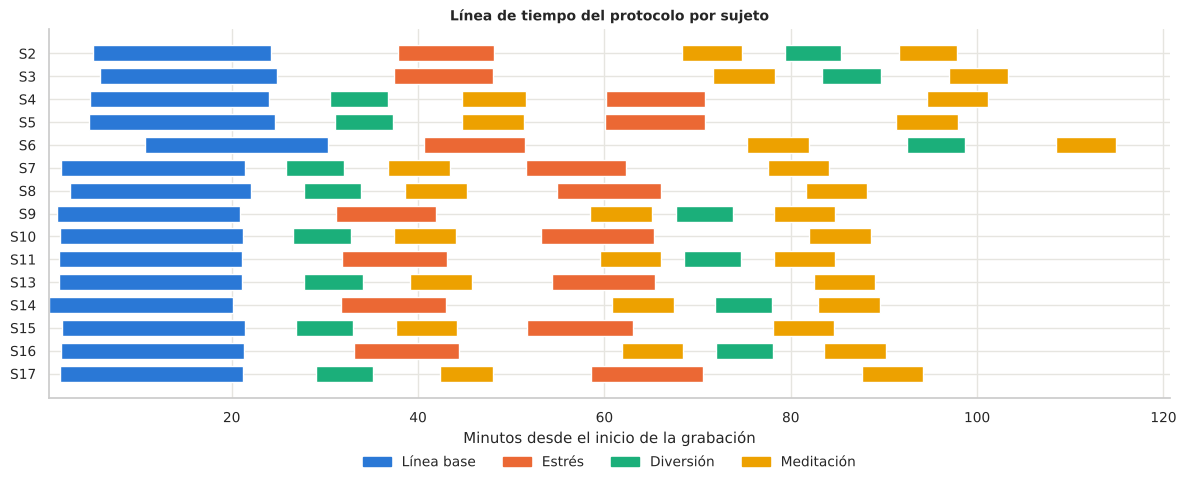

In [7]:
subs = sorted(bloques.sujeto.unique(), key=gr.subject_sort_key)
fig, ax = plt.subplots(figsize=(12, 5))
for i, s in enumerate(subs):
    for _, b in bloques[bloques.sujeto == s].iterrows():
        ax.barh(i, b.duracion_s / 60, left=b.inicio_s / 60, color=gr.COND_COLORS[b.condicion], height=0.7,
                edgecolor="white", linewidth=1)
ax.set_yticks(range(len(subs)), subs)
ax.invert_yaxis()
ax.set_xlabel("Minutos desde el inicio de la grabación")
ax.set_title("Línea de tiempo del protocolo por sujeto")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=gr.COND_COLORS[c], label=gr.COND_ES[c]) for c in cfg.COND_ORDER],
          ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.12), frameon=False)
fig.tight_layout(); gr.savefig(fig, "01_linea_tiempo_protocolo"); plt.show()

**Desbalance de clases.** La línea base dura casi el doble que el estrés y unas tres veces la diversión.
Esto importa en el objetivo 2: un modelo que siempre diga "línea base" acertaría mucho sin aprender nada.
Por eso las métricas del proyecto deben ser **F1 macro** o **exactitud balanceada**, no solo exactitud.

In [8]:
prop = minutos.drop(index="promedio")[["baseline", "stress", "amusement"]].sum()
(100 * prop / prop.sum()).round(1).rename("% del tiempo (3 clases)").to_frame()

,% del tiempo (3 clases)
condicion,
baseline,53.1
stress,30.1
amusement,16.8


## 3. Vista general: las 10 señales de cada sujeto durante toda la sesión
Para **cada uno de los 15 sujetos** graficamos sus 10 señales **crudas** (tal como vienen), con las condiciones
sombreadas. Para los acelerómetros se grafica la **magnitud** (la combinación de los 3 ejes). Cada figura se guarda
también en `salidas/figuras/01_sesion_completa_S{id}.png`.

**Qué buscar:** cambios visibles en las zonas de estrés (naranja), tramos planos o con valores absurdos,
saltos bruscos, y diferencias entre sujetos (por ejemplo, la temperatura de pecho de S2 y S17, cuyo sensor estaba
mal adherido según las notas).

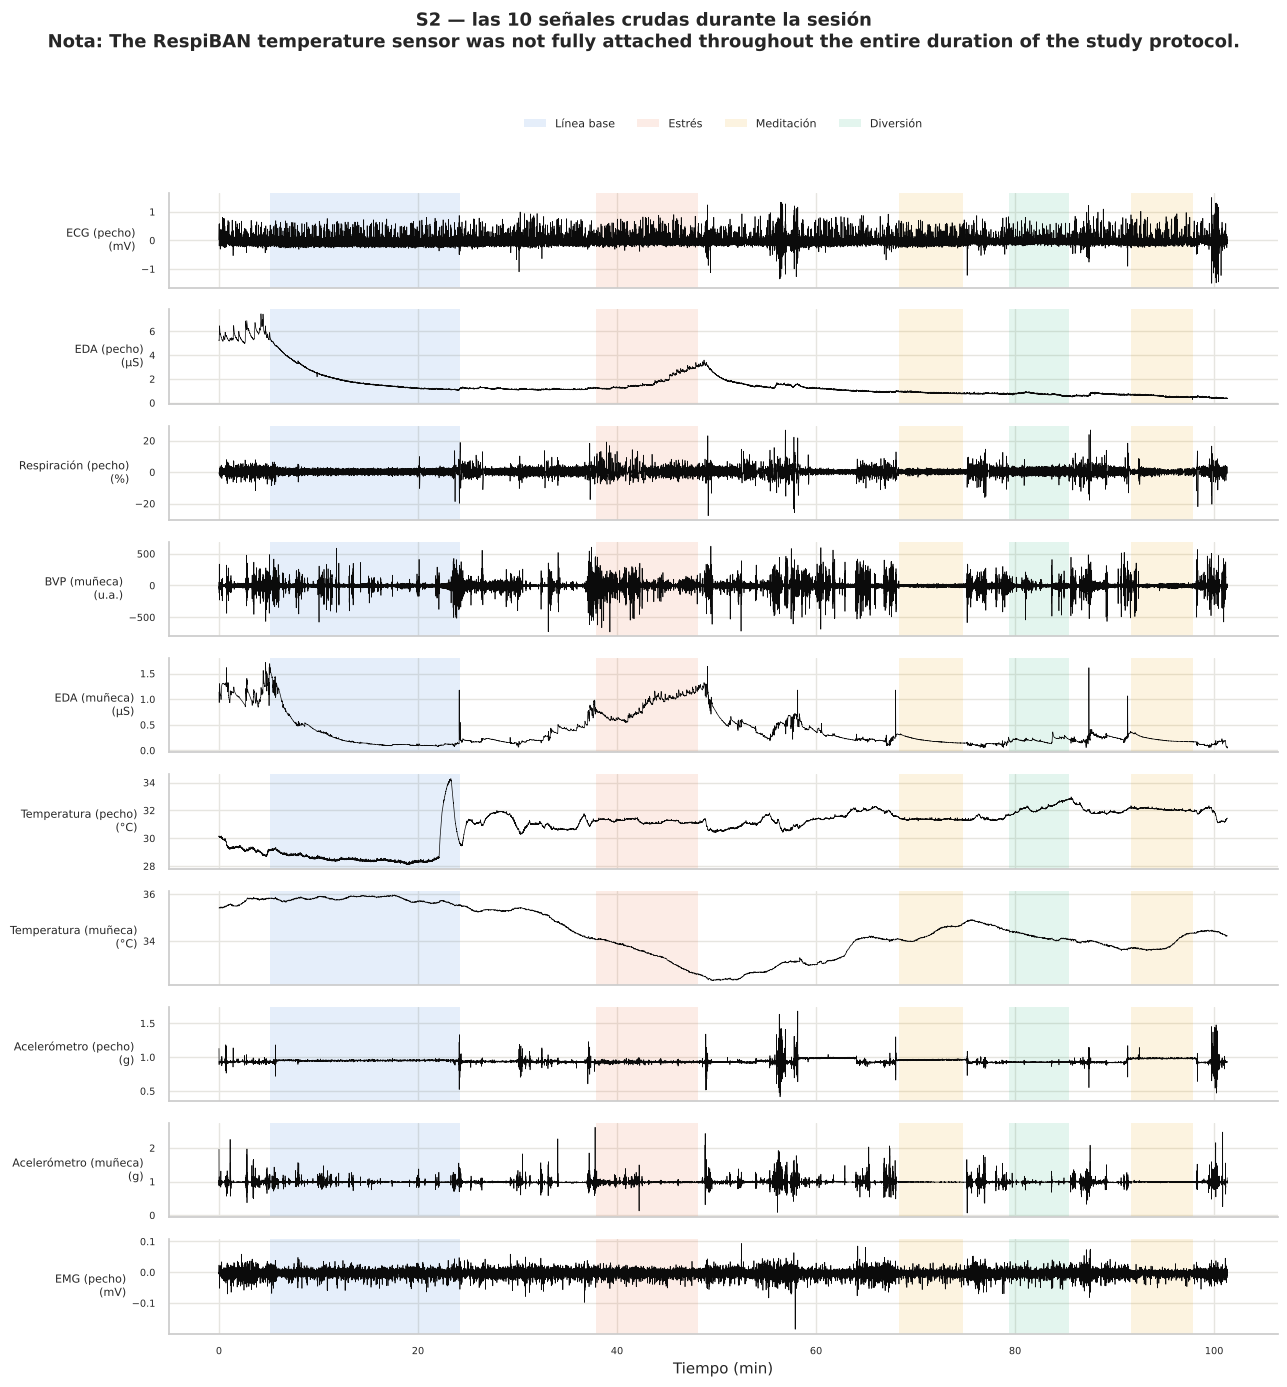

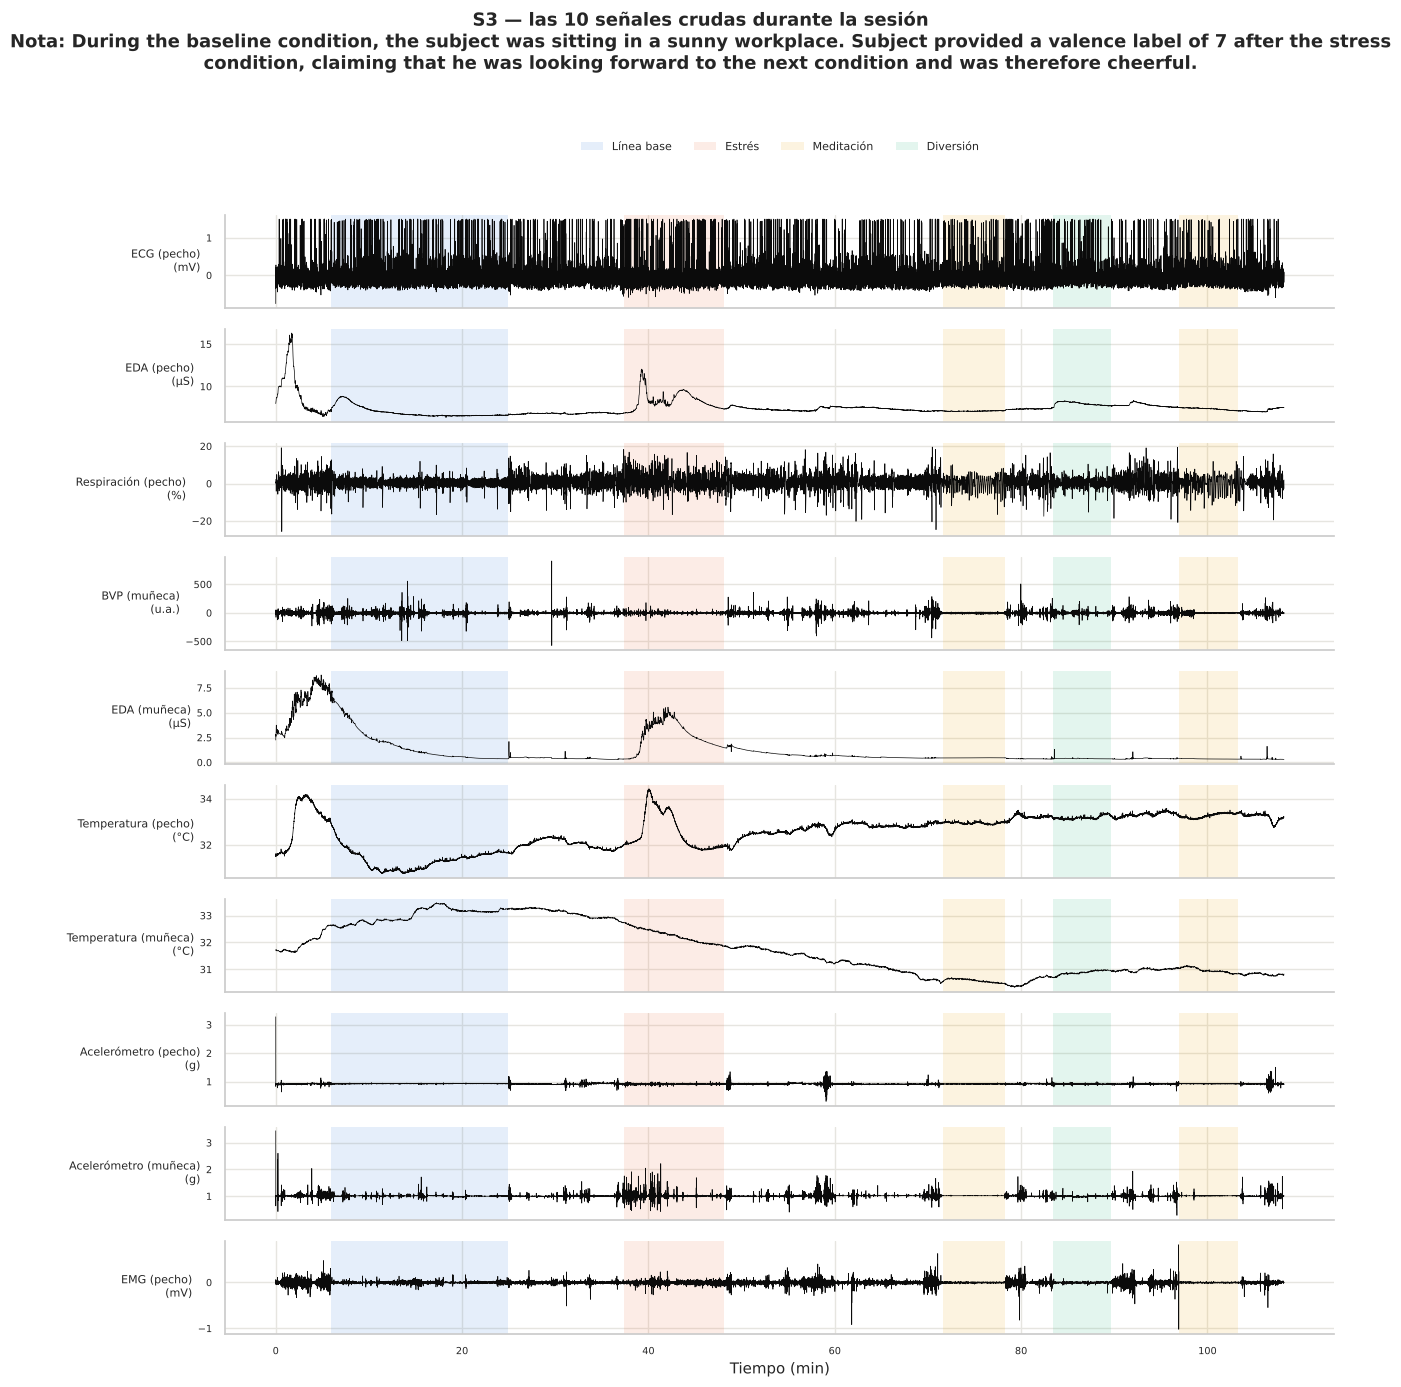

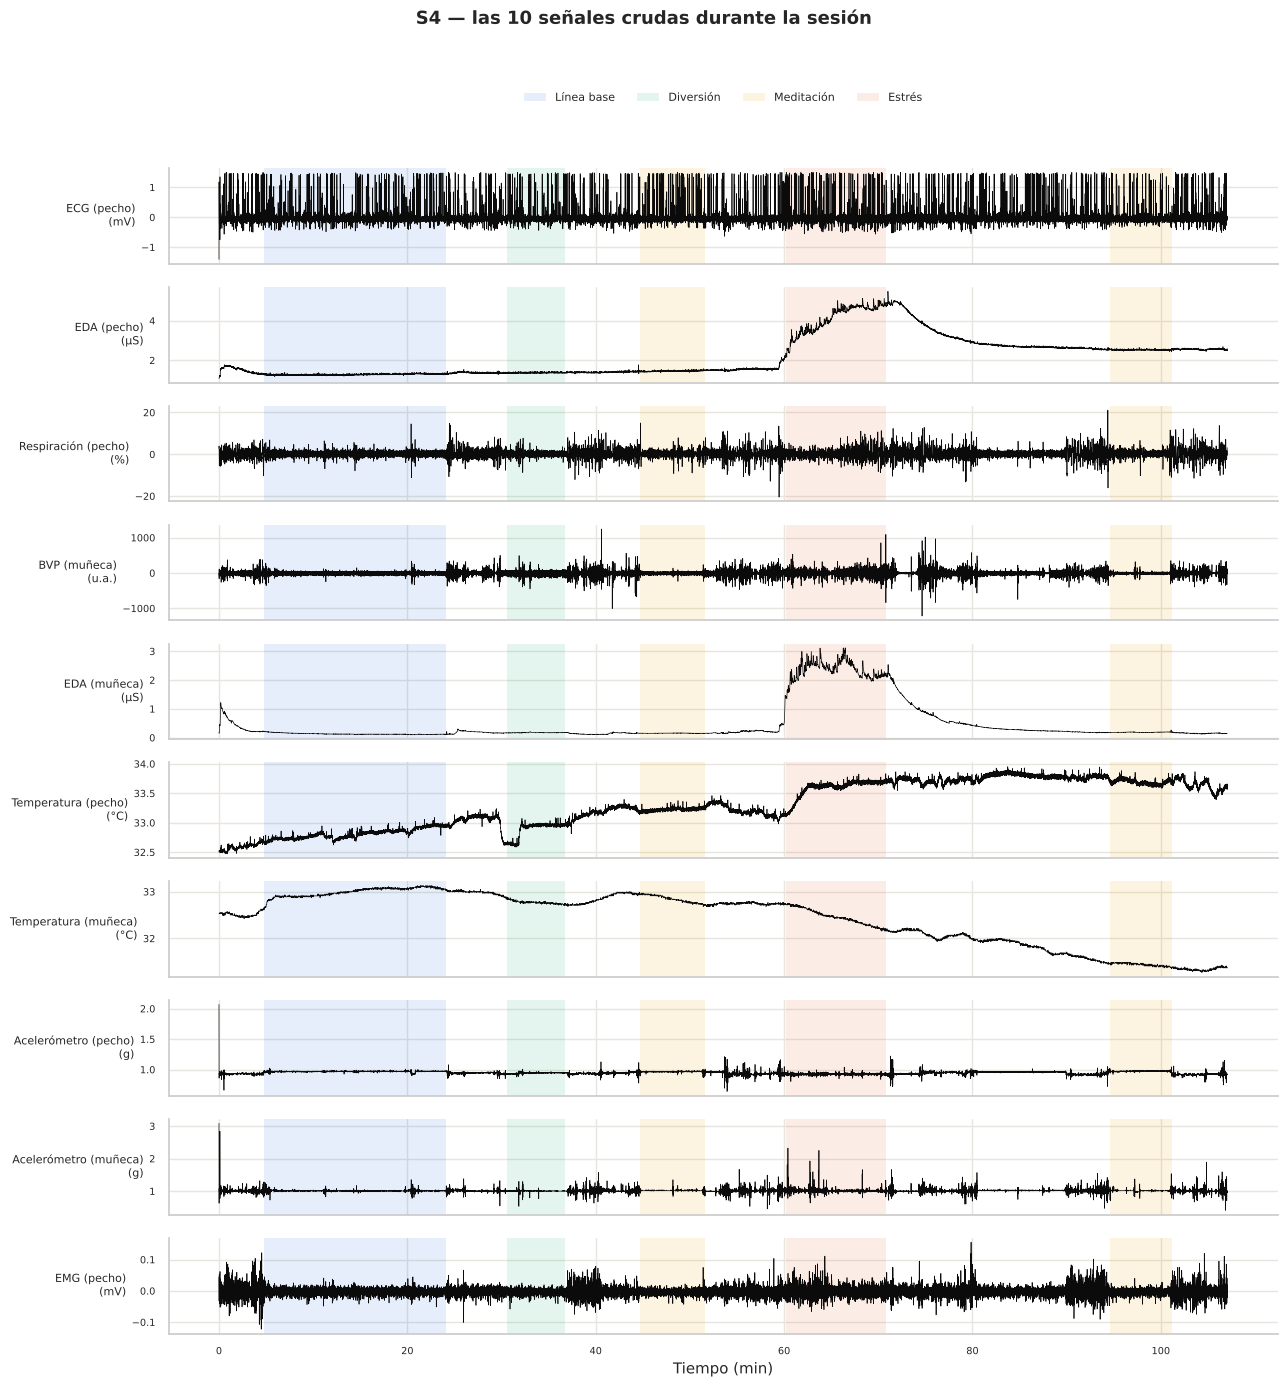

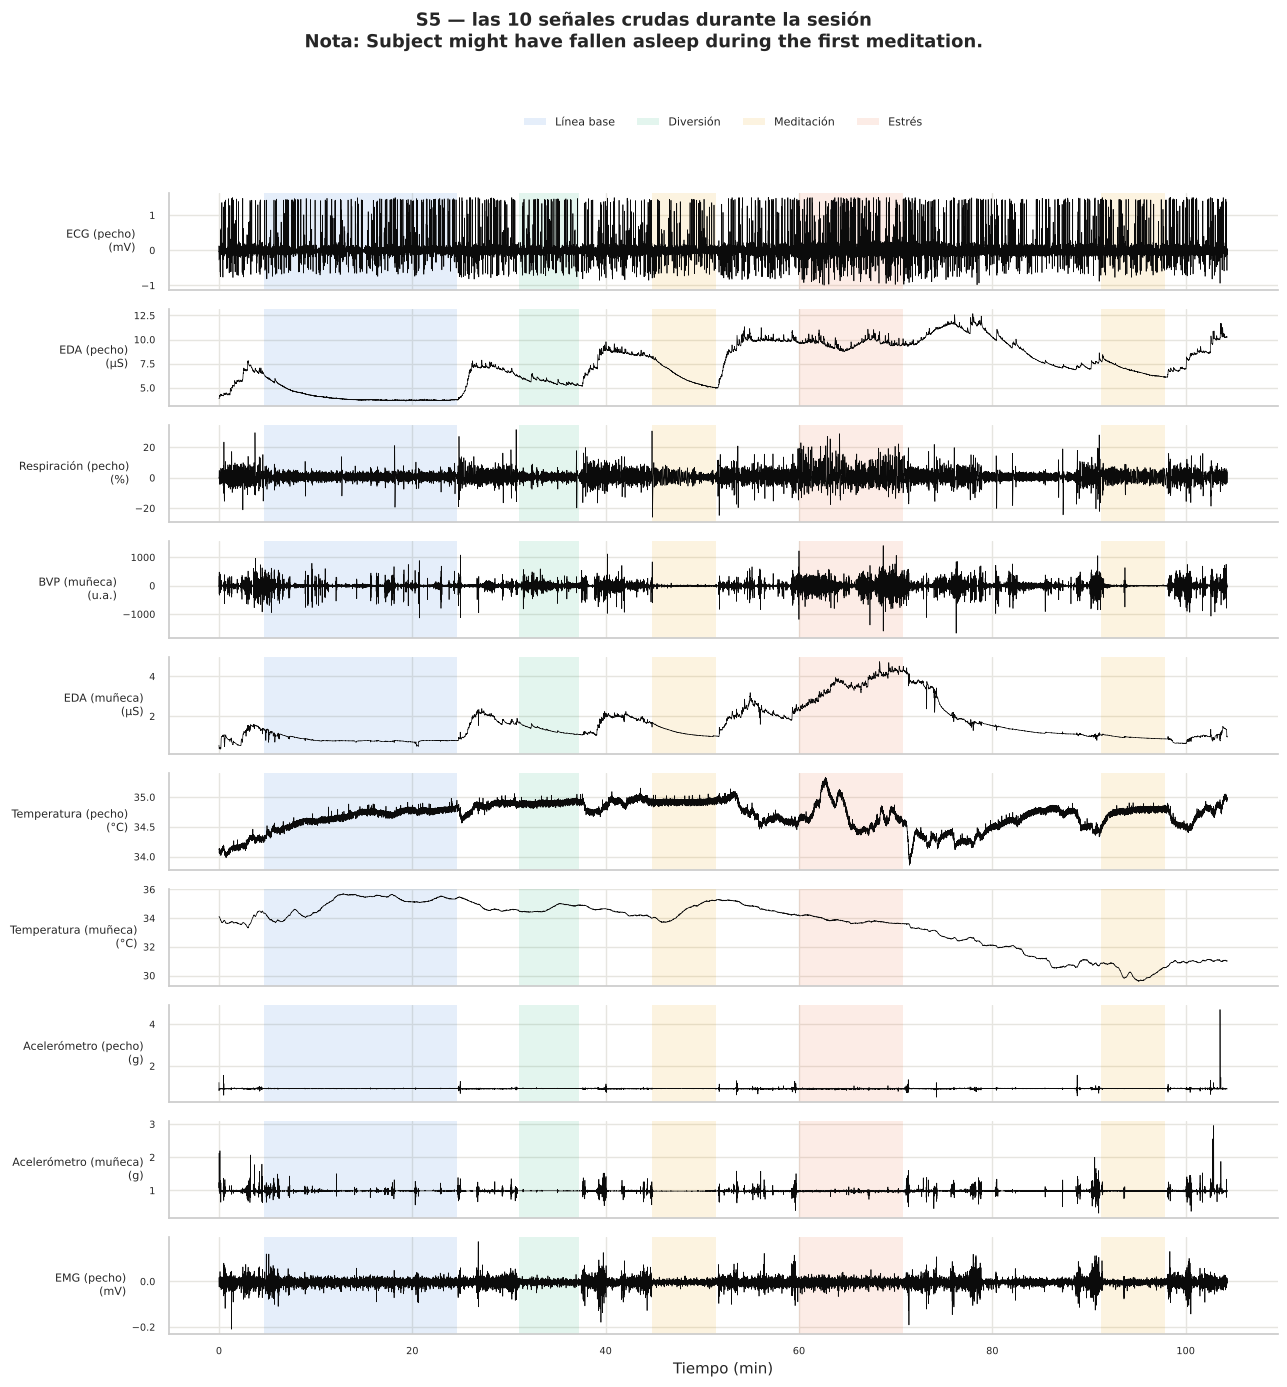

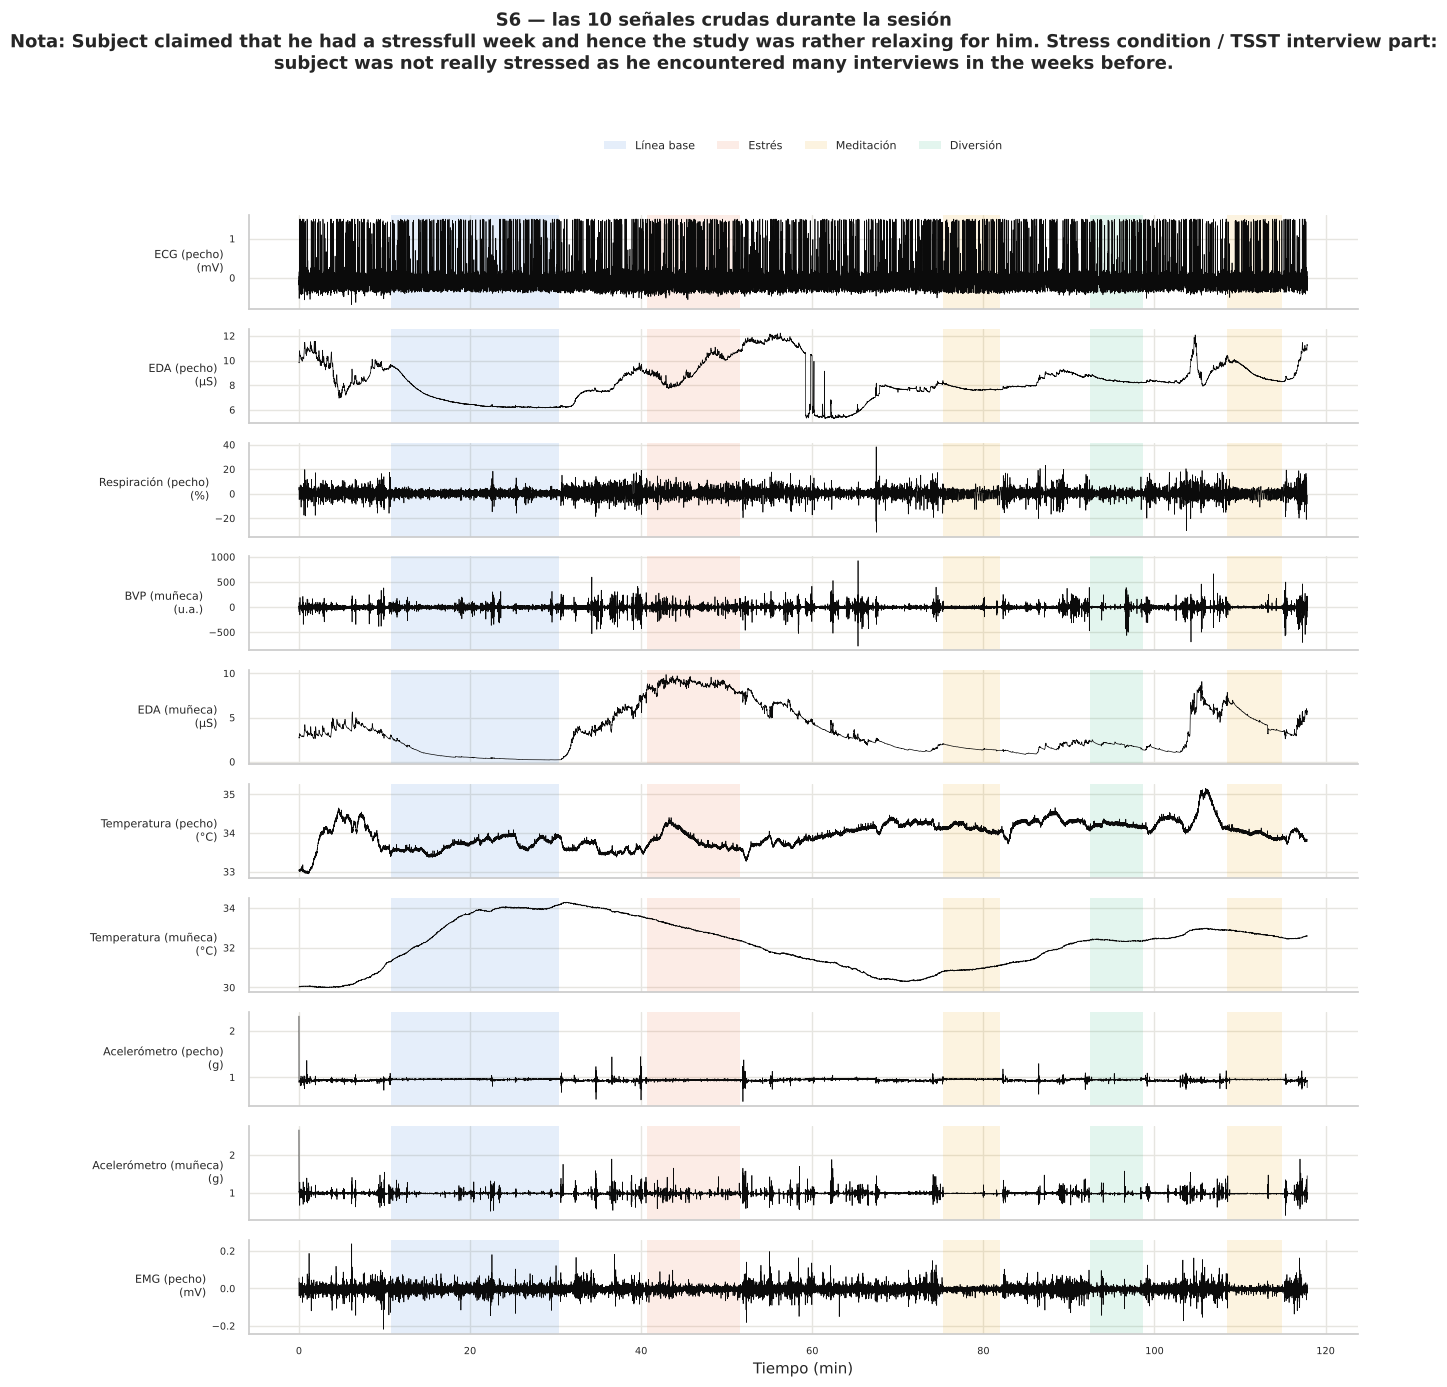

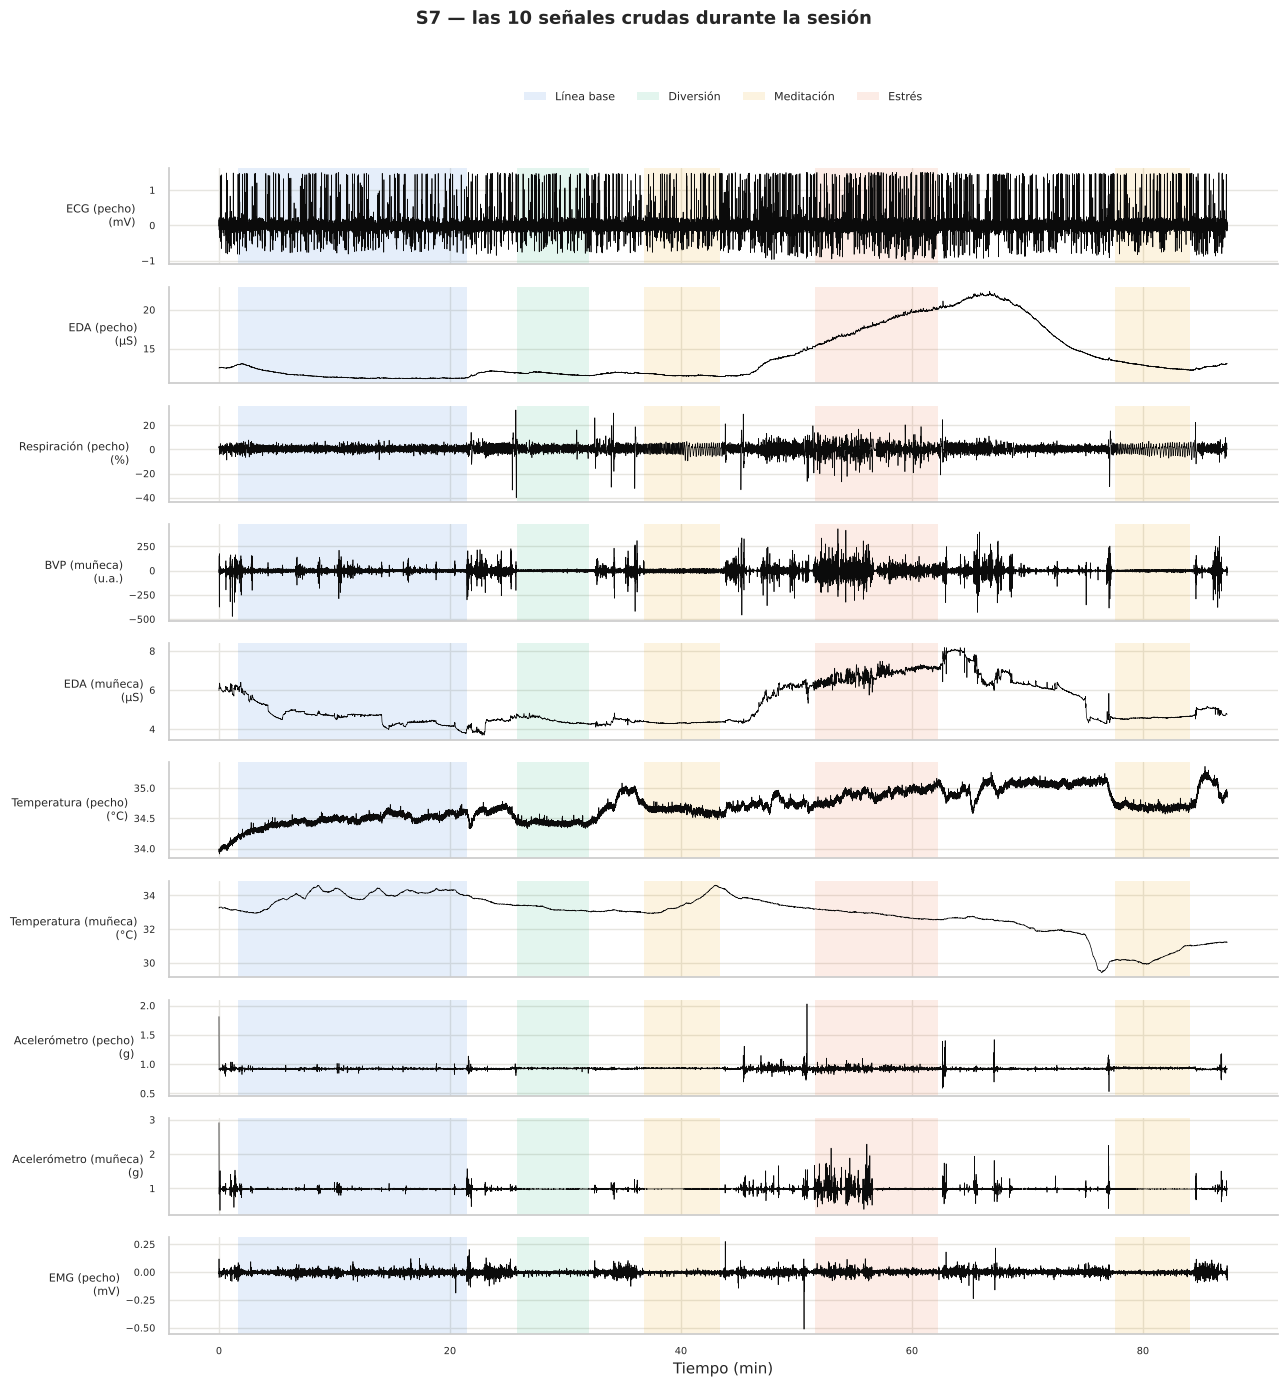

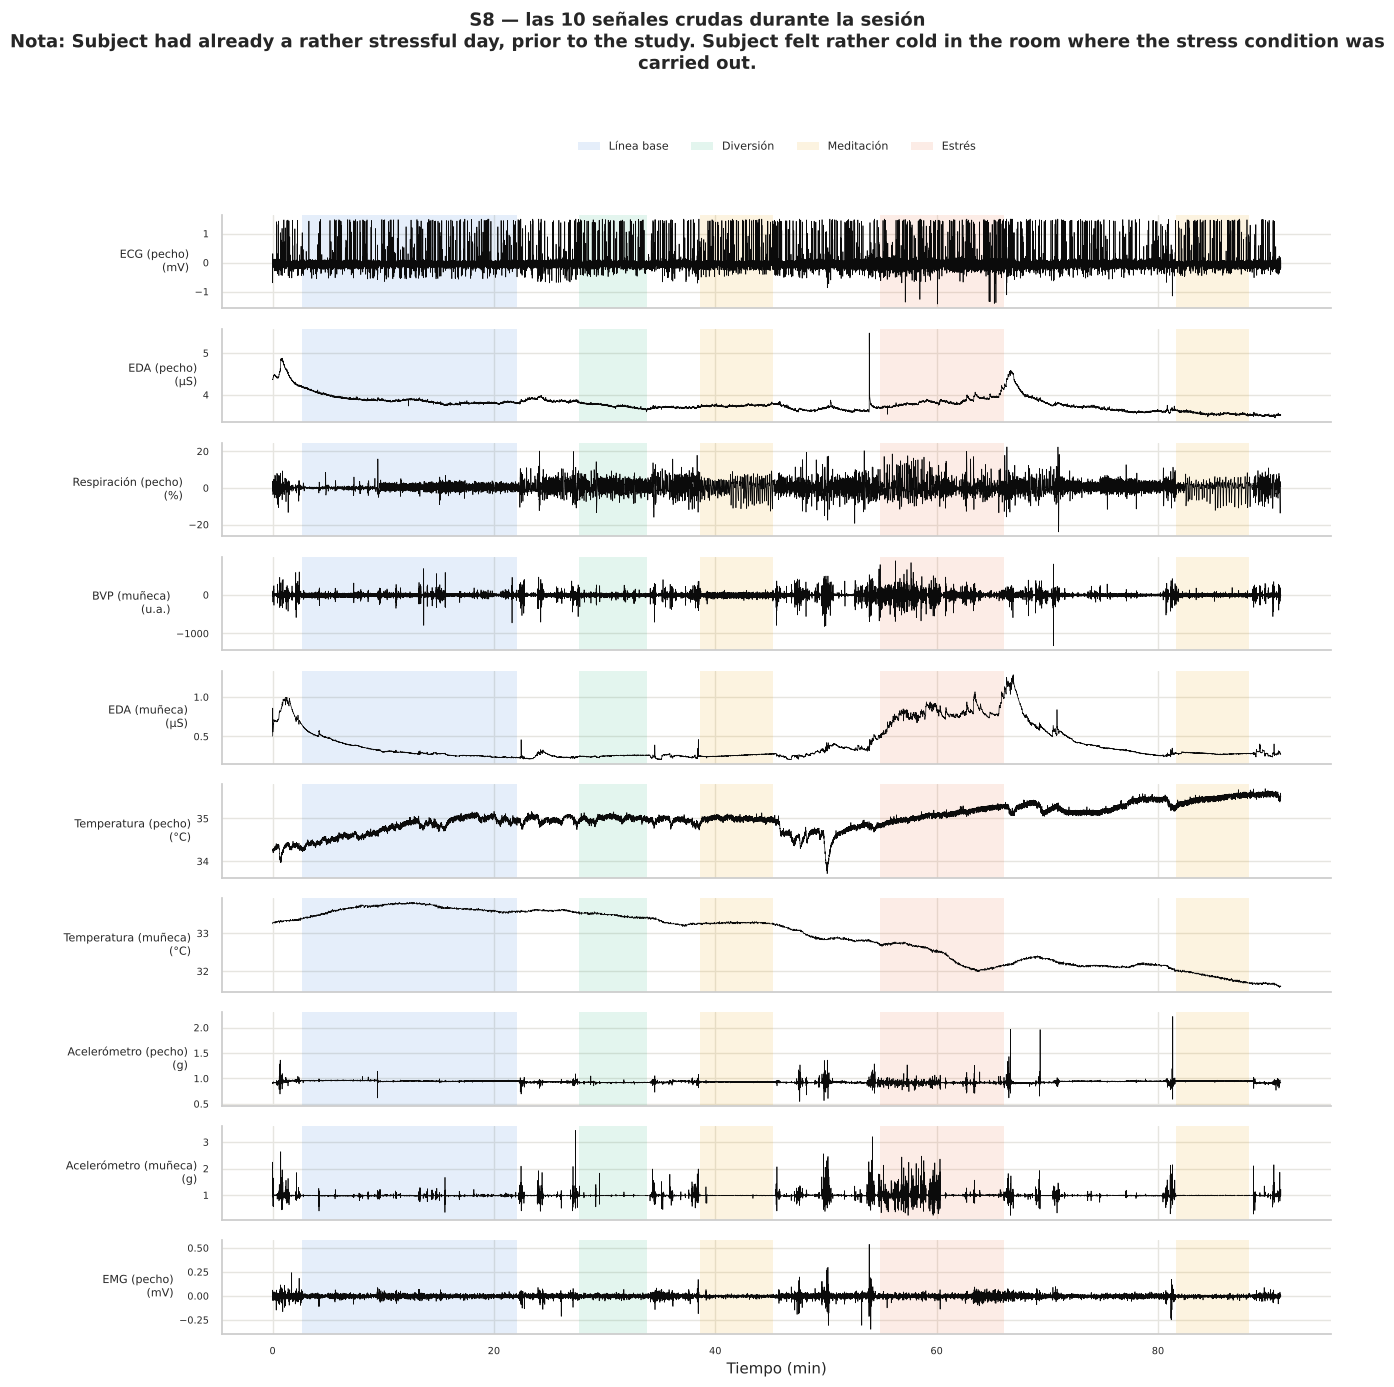

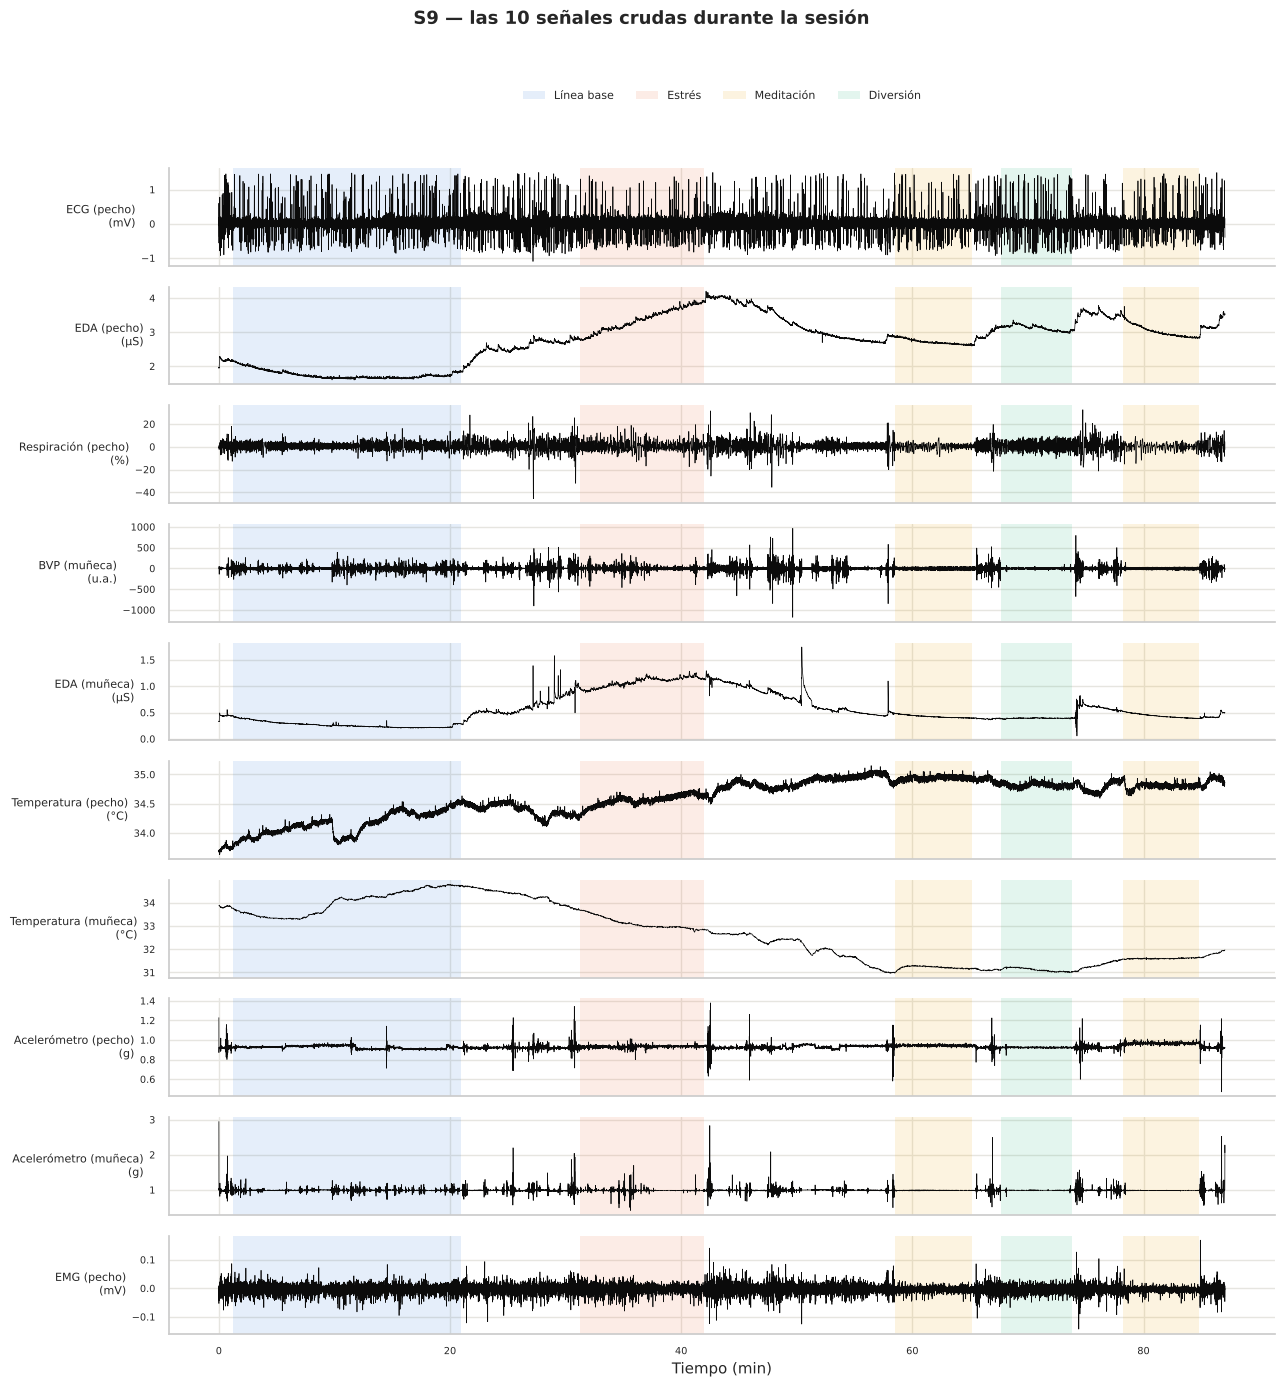

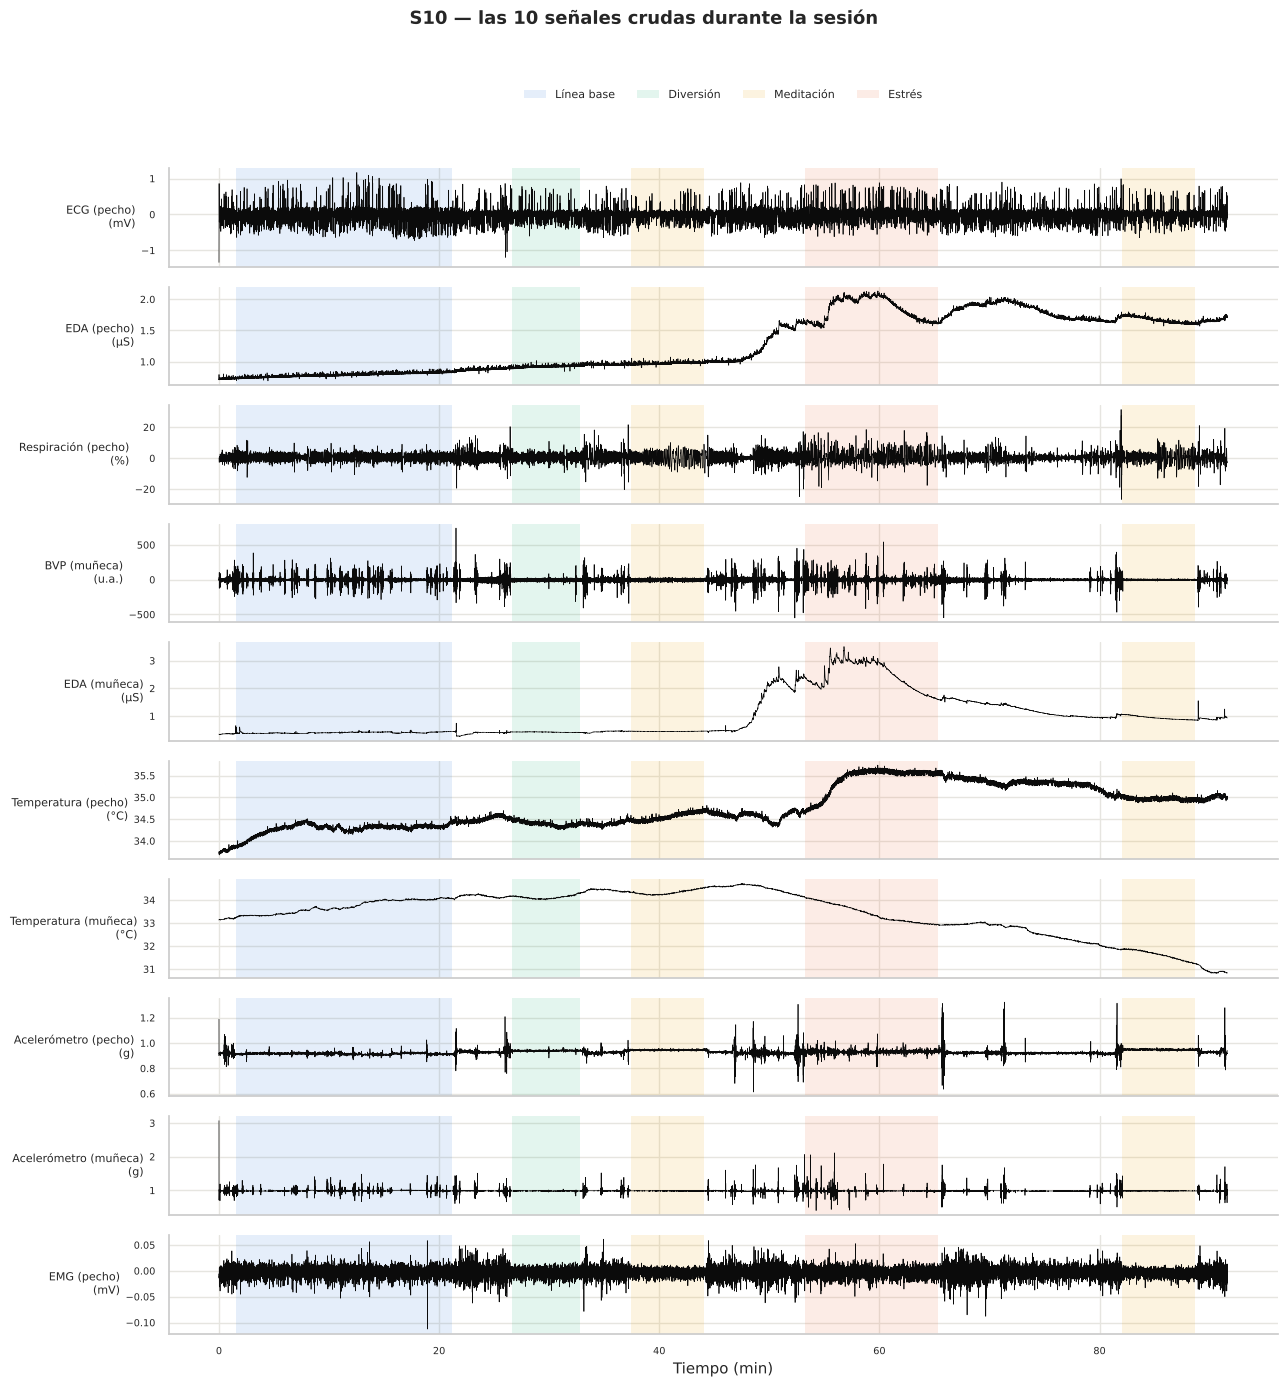

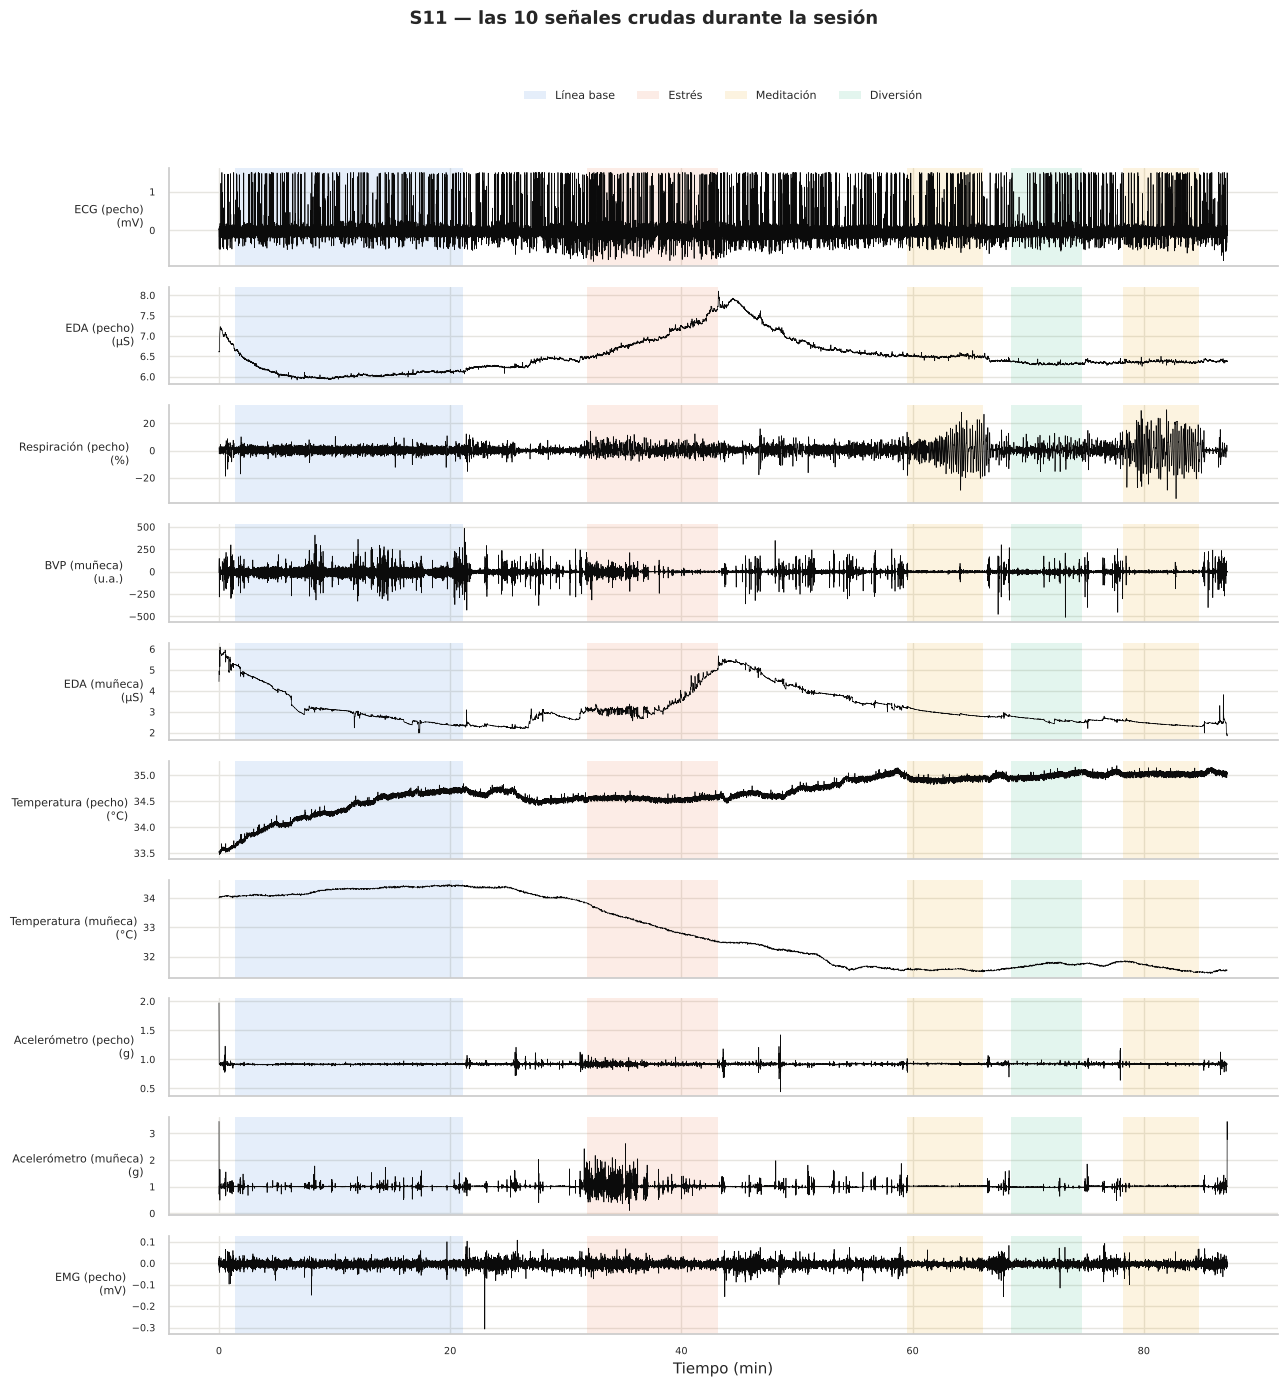

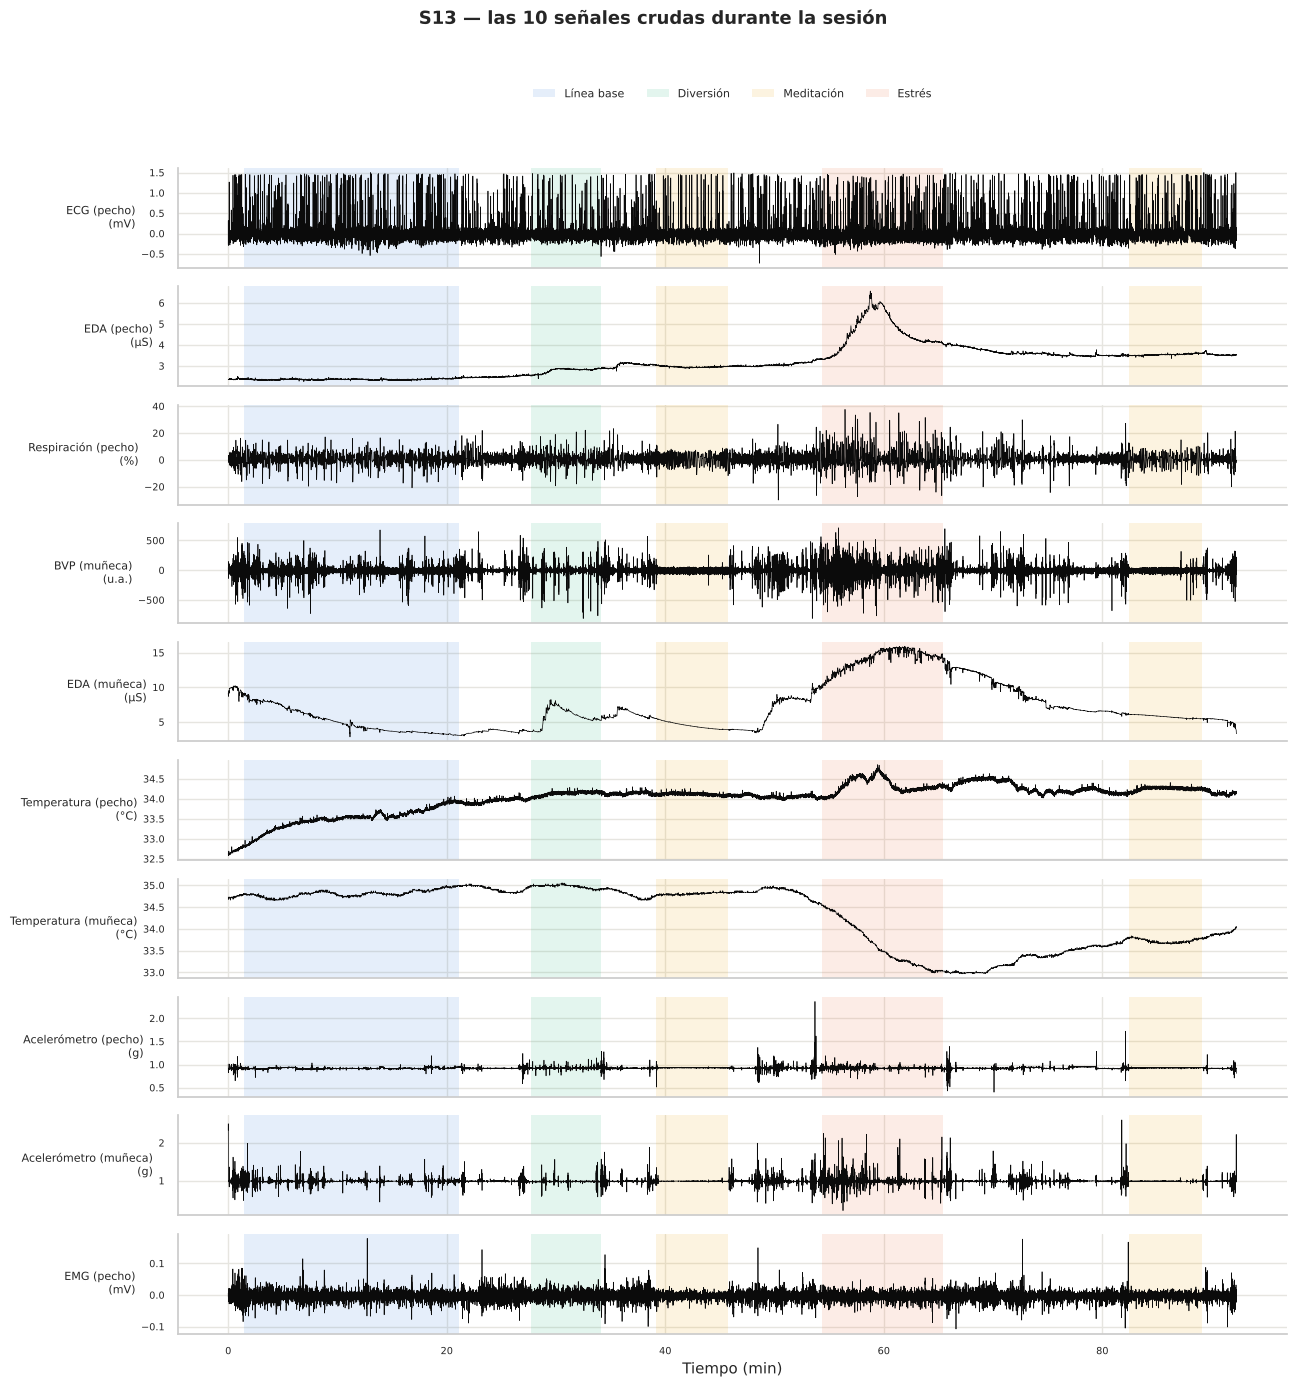

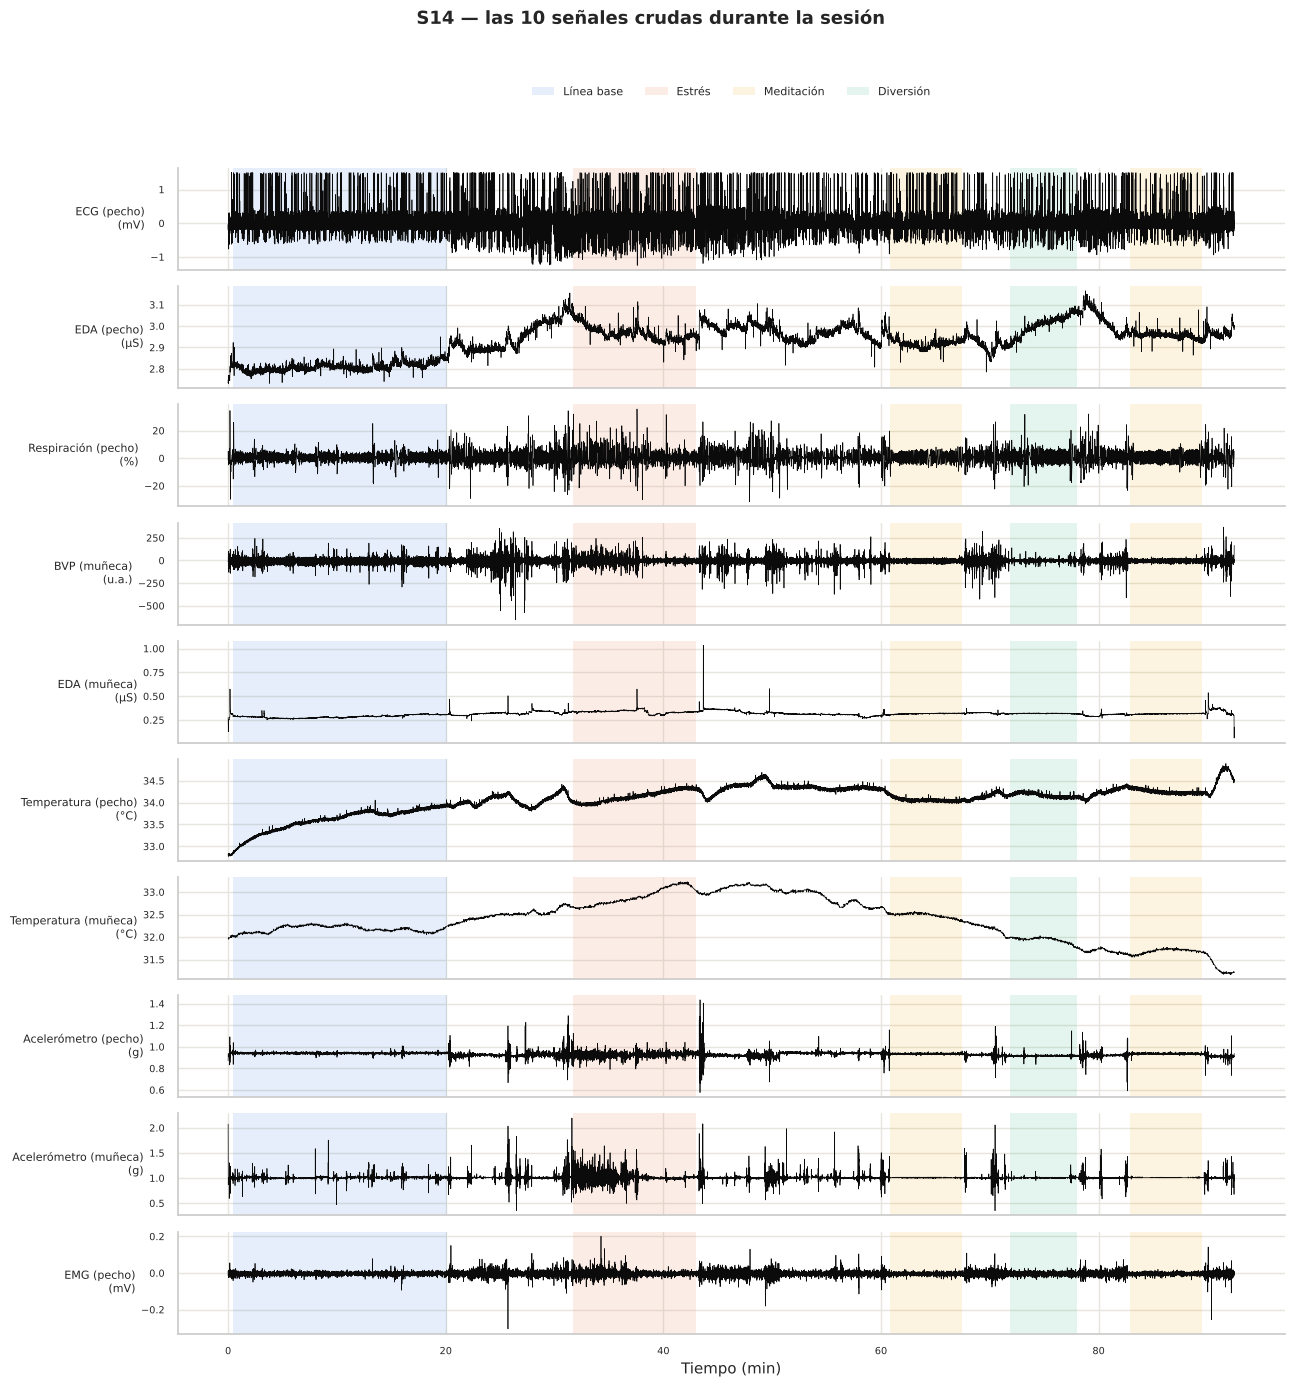

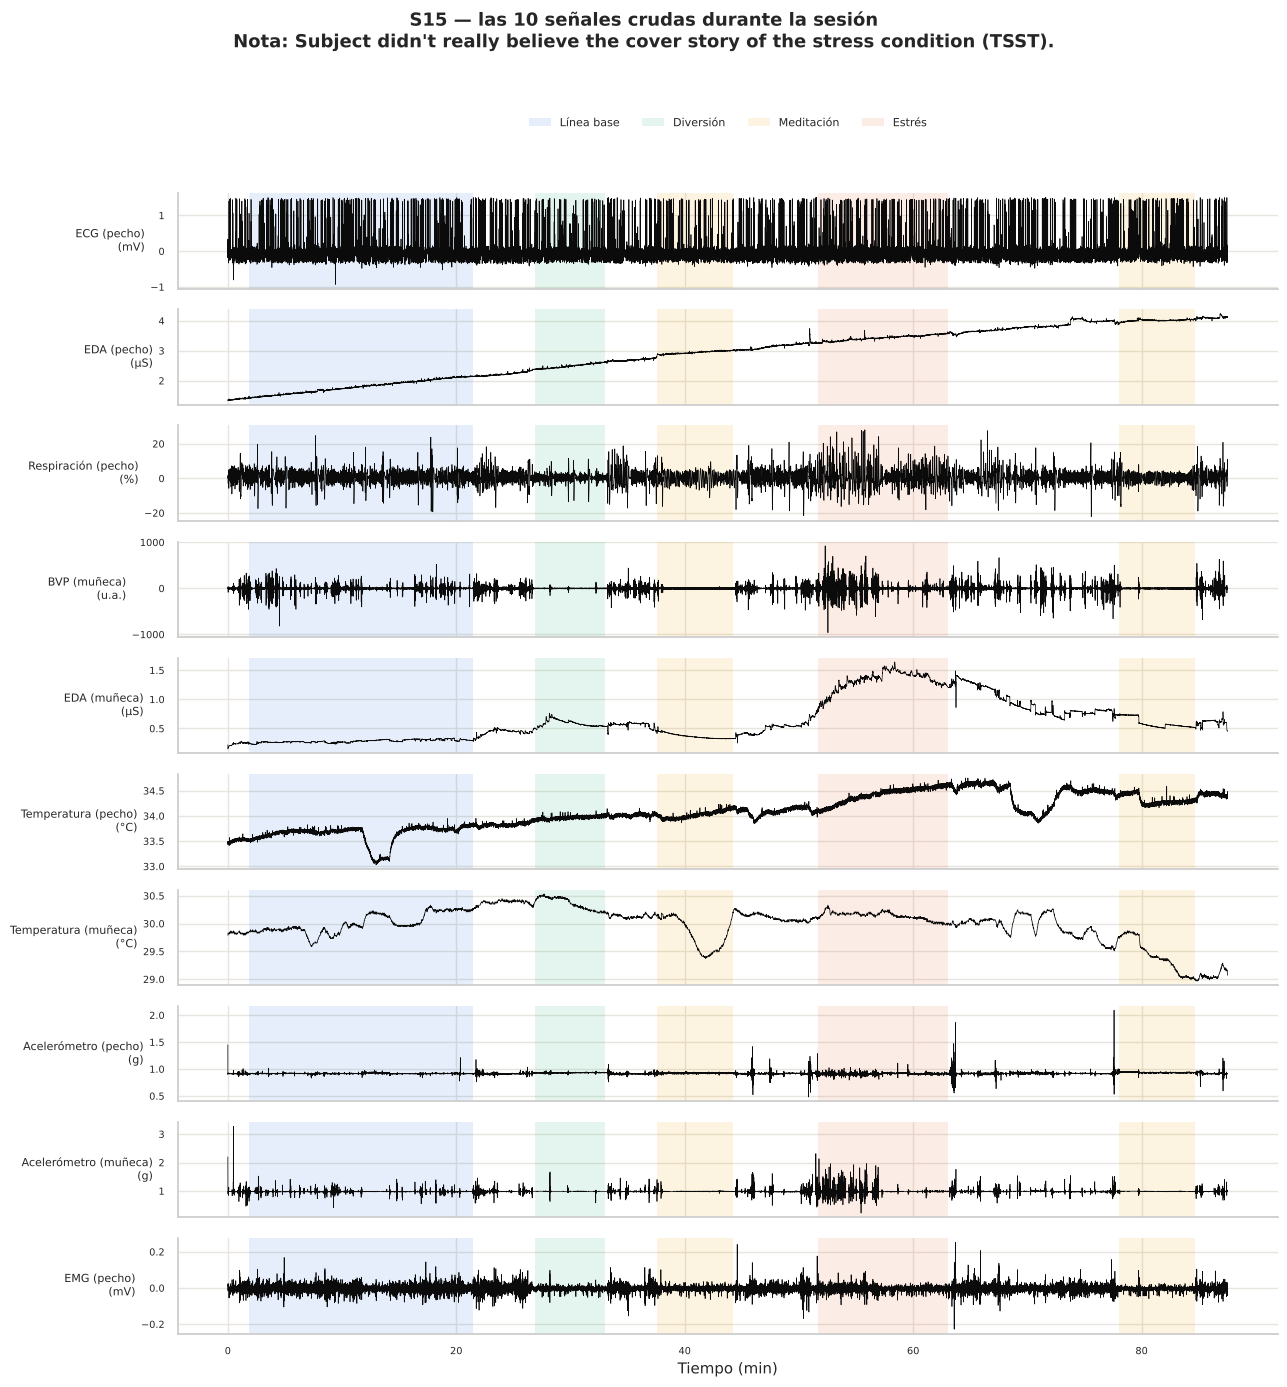

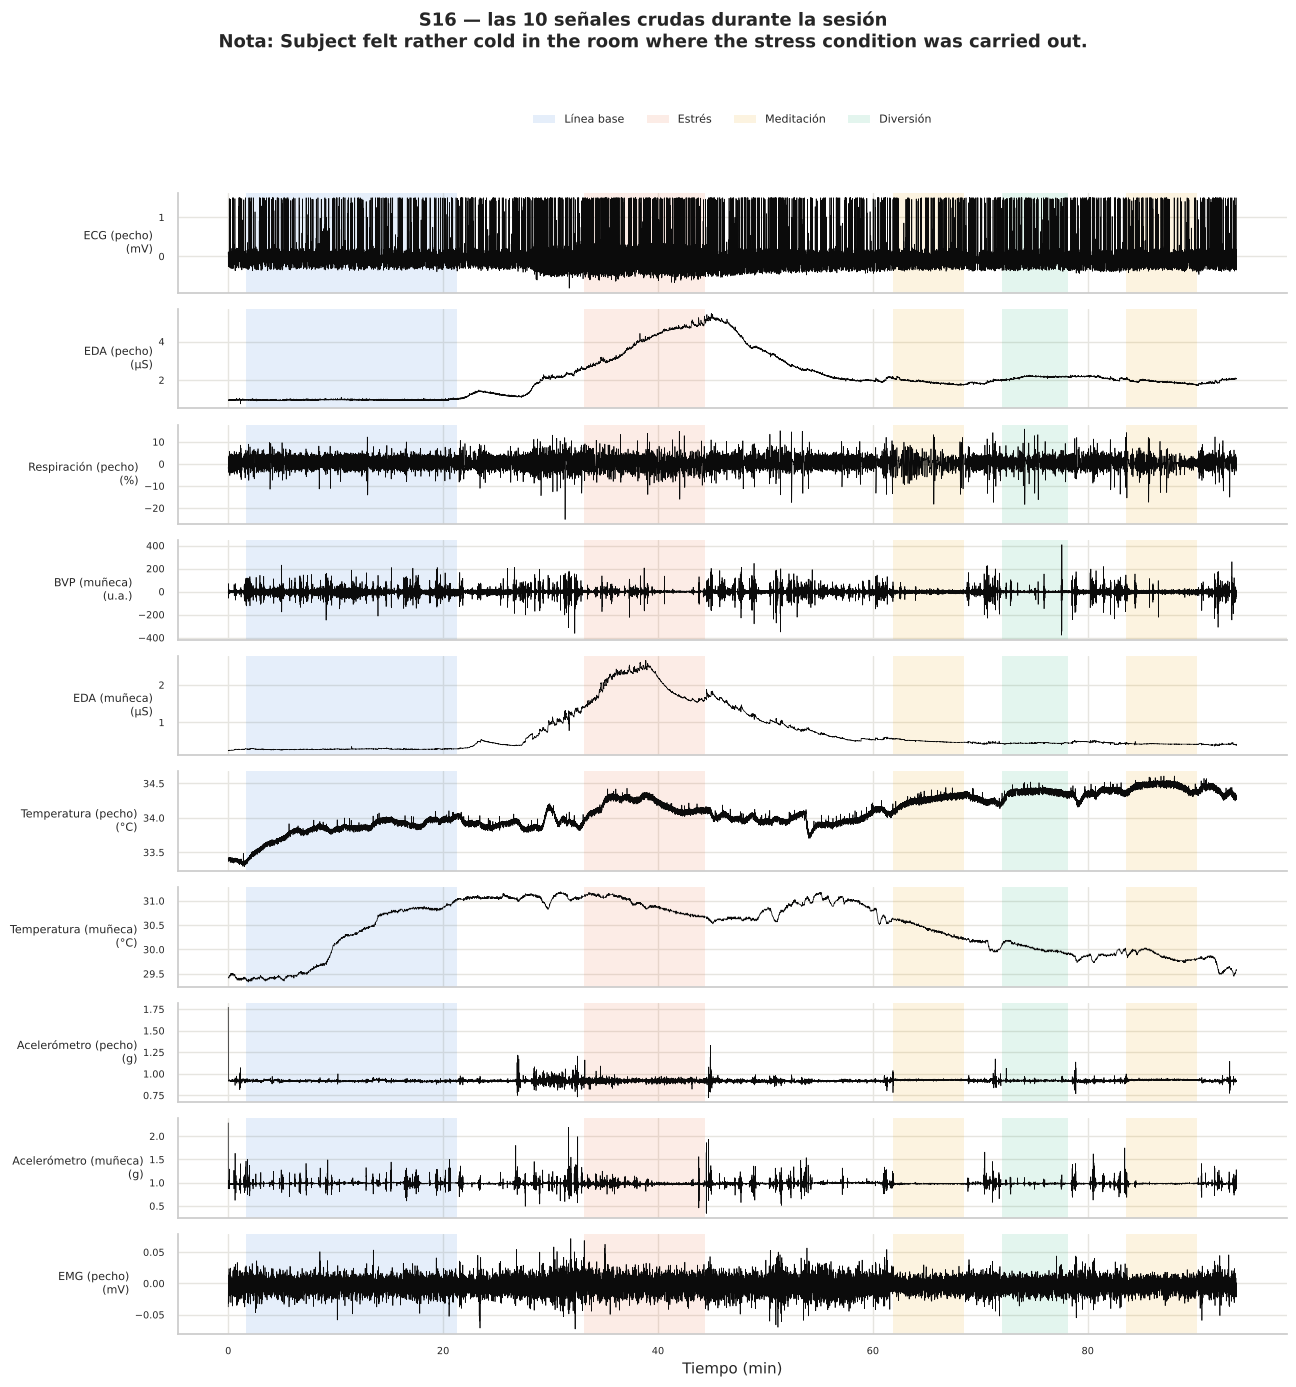

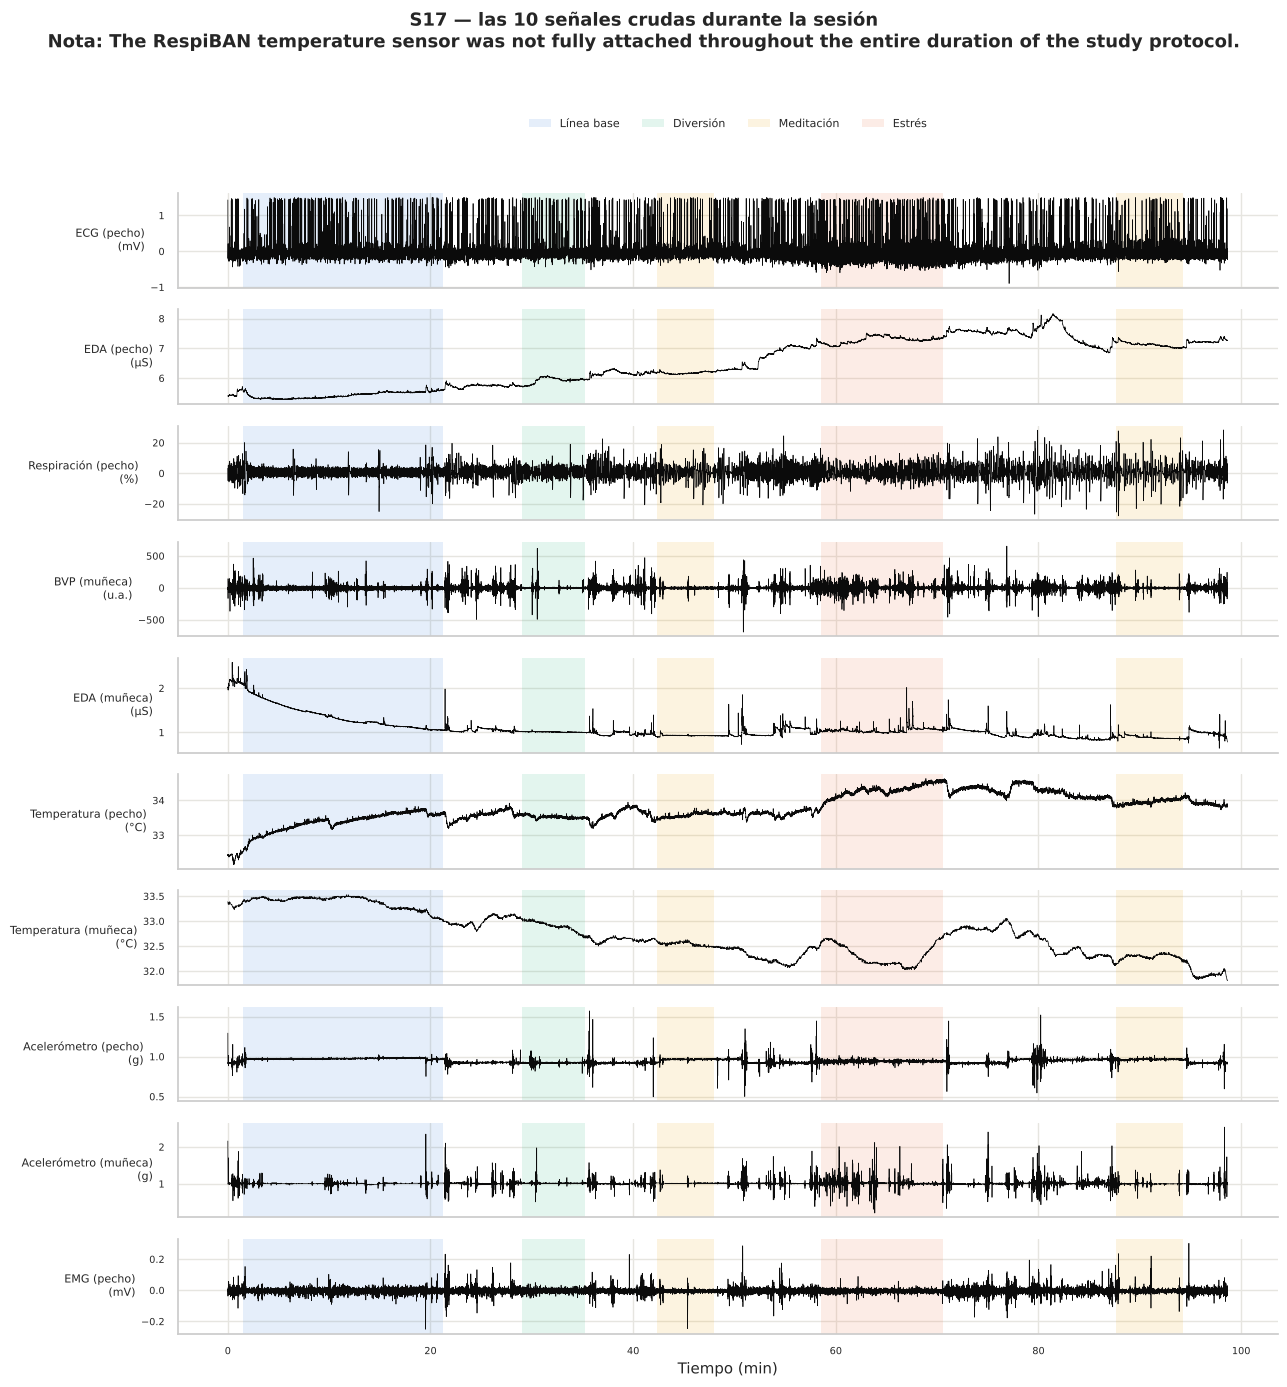

In [9]:
import textwrap
for sid in SUBJECTS:
    data = carga.load_subject(DATA_PATH, sid)
    b = etiquetas.condition_blocks(data["label"])
    señales = [(cfg.SIGNALS[k]["name"], carga.magnitude(carga.get_signal(data, k)), cfg.SIGNALS[k]["fs"],
                cfg.SIGNALS[k]["unit"]) for k in cfg.ALL_SIGNALS]
    nota = notas.get(f"S{sid}", "")
    titulo = f"S{sid} — las 10 señales crudas durante la sesión"
    if nota:
        titulo += "\n" + "\n".join(textwrap.wrap("Nota: " + nota, 140))
    fig = gr.plot_session(señales, b, titulo)
    gr.savefig(fig, f"01_sesion_completa_S{sid}"); plt.show(); plt.close(fig)
    del data, señales; _ = gc.collect()

## 4. Distribución de cada señal por condición (todos los sujetos)
Para comparar condiciones sin cargar millones de muestras, tomamos **un valor por segundo** (la mediana de cada
segundo) dentro de cada condición, para los 15 sujetos.

Dos vistas:
- **Valores absolutos**: muestran el rango real de cada señal (sirve para revisar que los rangos sean fisiológicos).
- **Cambio respecto a la línea base de cada sujeto**: como cada persona tiene su propio nivel (p. ej. una suda
  más que otra), restamos su mediana de línea base. Así se ve mejor si la condición **mueve** la señal.

Ojo: para ECG, BVP, respiración y EMG, que oscilan alrededor de cero, el valor por segundo dice poco del estado
fisiológico; para esas señales lo informativo son los **marcadores** (frecuencia cardíaca, frecuencia respiratoria…),
que se calculan en el notebook 04.

In [10]:
per_second = []
for sid in SUBJECTS:
    data = carga.load_subject(DATA_PATH, sid)
    label = data["label"]
    for key, spec in cfg.SIGNALS.items():
        x = carga.magnitude(carga.get_signal(data, key))
        fs = spec["fs"]
        n_s = len(x) // fs
        sec = np.median(x[: n_s * fs].reshape(n_s, fs), axis=1)
        lab = etiquetas.label_at_fs(label, 1, n_s)
        keep = np.isin(lab, list(cfg.CONDITIONS))
        per_second.append(pd.DataFrame({"sujeto": f"S{sid}", "señal": key, "condicion": pd.Series(lab[keep]).map(cfg.CONDITIONS).values,
                                        "valor": sec[keep]}))
    del data; _ = gc.collect()
per_second = pd.concat(per_second, ignore_index=True)
base_med = per_second[per_second.condicion == "baseline"].groupby(["sujeto", "señal"]).valor.median().rename("base")
per_second = per_second.join(base_med, on=["sujeto", "señal"])
per_second["delta"] = per_second.valor - per_second.base
per_second.groupby(["señal", "condicion"]).valor.describe(percentiles=[.01, .5, .99]).round(3)

count    mean     std      min       1%     50%      99%      max
señal      condicion                                                                      
chest_ACC  amusement    5575.0   0.927   0.010    0.903    0.909   0.925    0.950    0.968
           baseline    17611.0   0.935   0.020    0.883    0.904   0.928    0.982    0.984
           meditation  11806.0   0.941   0.017    0.905    0.917   0.935    0.982    0.984
           stress       9966.0   0.924   0.010    0.894    0.904   0.923    0.944    0.977
chest_ECG  amusement    5575.0  -0.024   0.028   -0.223   -0.106  -0.023    0.039    0.149
           baseline    17611.0  -0.026   0.027   -0.209   -0.075  -0.030    0.051    0.191
           meditation  11806.0  -0.024   0.024   -0.239   -0.080  -0.025    0.035    0.178
           stress       9966.0  -0.029   0.037   -0.257   -0.136  -0.027    0.044    0.157
chest_EDA  amusement    5575.0   4.426   3.064    0.545    0.639   3.140   11.938   12.055
           baseline    17611.0   3.907   2.918    0.731    0.752   2.816   12.031   13.058
           meditation  11806.0   4.617   3.083    0.455    0.480   3.536   12.974   13.430
           stress       9966.0   5.921   4.092    1.170    1.257   4.282   19.842   20.332
chest_EMG  amusement    5575.0  -0.003   0.001   -0.009   -0.005  -0.003   -0.001   -0.000
           baseline    17611.0  -0.003   0.001   -0.021   -0.005  -0.002   -0.001    0.004
           meditation  11806.0  -0.003   0.001   -0.009   -0.004  -0.002   -0.001    0.004
           stress       9966.0  -0.003   0.002   -0.015   -0.005  -0.003    0.003    0.005
chest_Resp amusement    5575.0   0.019   3.156  -19.121   -8.833  -0.221    8.054   28.215
           baseline    17611.0   0.024   2.795  -23.824   -8.116  -0.200    7.032   23.375
           meditation  11806.0   0.034   4.219  -34.061  -12.779   0.161   11.617   28.456
           stress       9966.0   0.033   4.540  -25.126  -10.813  -0.443   13.944   33.369
chest_Temp amusement    5575.0  34.096   0.796   31.638   31.901  34.250   35.076   35.090
           baseline    17611.0  33.458   1.502   28.158   28.322  33.808   35.031   35.119
           meditation  11806.0  34.178   0.882   31.290   31.327  34.286   35.541   35.594
           stress       9966.0  34.165   1.029   31.023   31.078  34.364   35.631   35.653
wrist_ACC  amusement    5575.0   0.990   0.013    0.904    0.971   0.985    1.020    1.095
           baseline    17611.0   0.993   0.014    0.919    0.970   0.989    1.027    1.110
           meditation  11806.0   0.994   0.016    0.943    0.973   0.987    1.027    1.046
           stress       9966.0   0.994   0.022    0.696    0.956   0.987    1.060    1.321
wrist_BVP  amusement    5575.0   3.643  18.081 -195.085  -55.599   2.125   63.267  231.265
           baseline    17611.0   4.359  22.728 -332.745  -72.530   4.340   71.281  257.850
           meditation  11806.0   3.758   9.910 -250.970  -21.722   2.865   28.650  126.055
           stress       9966.0   1.373  36.481 -422.585 -117.556   1.060  119.457  472.375
wrist_EDA  amusement    5575.0   1.365   1.691    0.131    0.165   0.445    7.228    8.134
           baseline    17611.0   1.329   1.744    0.075    0.100   0.397    7.698    9.085
           meditation  11806.0   1.397   1.684    0.143    0.152   0.474    6.051    7.769
           stress       9966.0   3.416   3.658    0.297    0.319   2.137   15.520   15.884
wrist_TEMP amusement    5575.0  32.587   1.512   29.890   29.950  32.760   35.000   35.050
           baseline    17611.0  33.349   1.587   29.330   29.430  33.580   35.910   35.970
           meditation  11806.0  32.008   1.514   28.990   29.250  31.710   34.870   35.270
           stress       9966.0  32.640   1.011   29.970   30.030  32.775   34.290   34.550

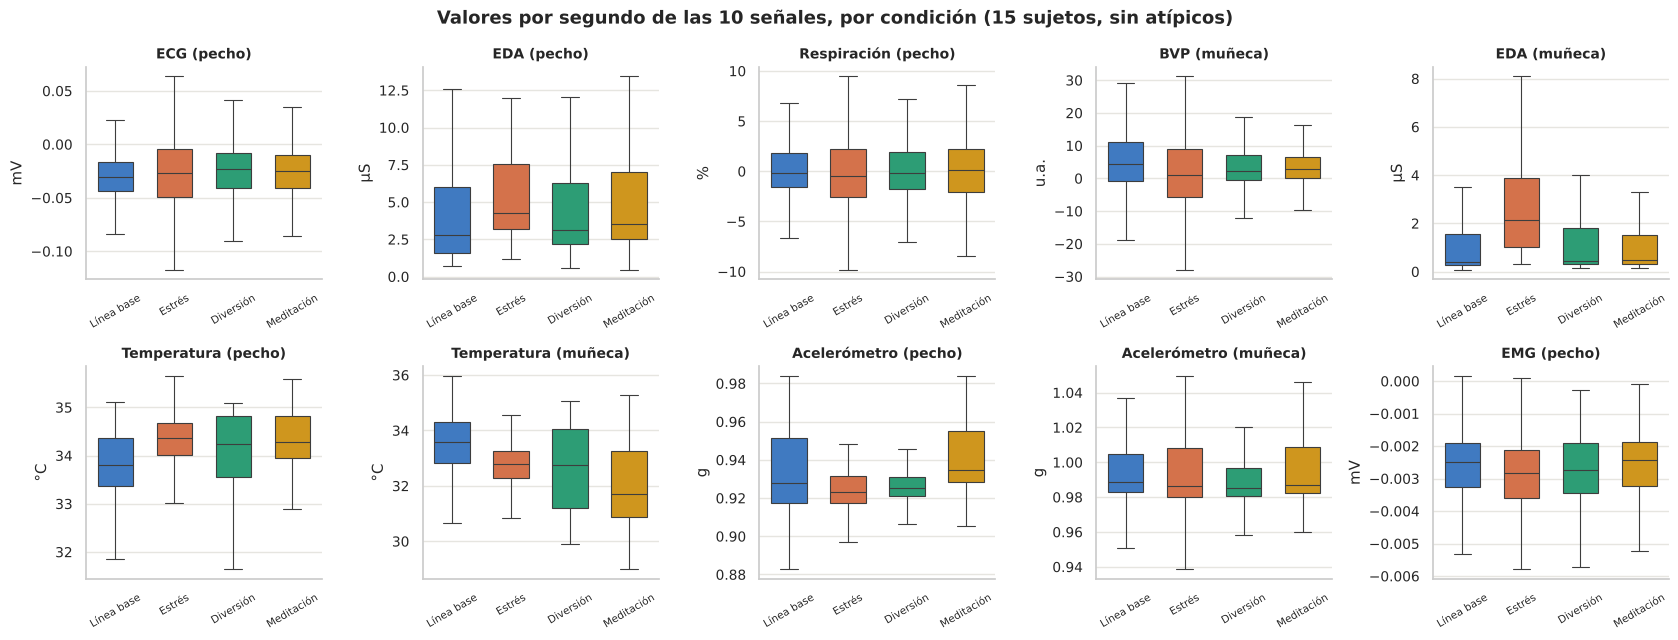

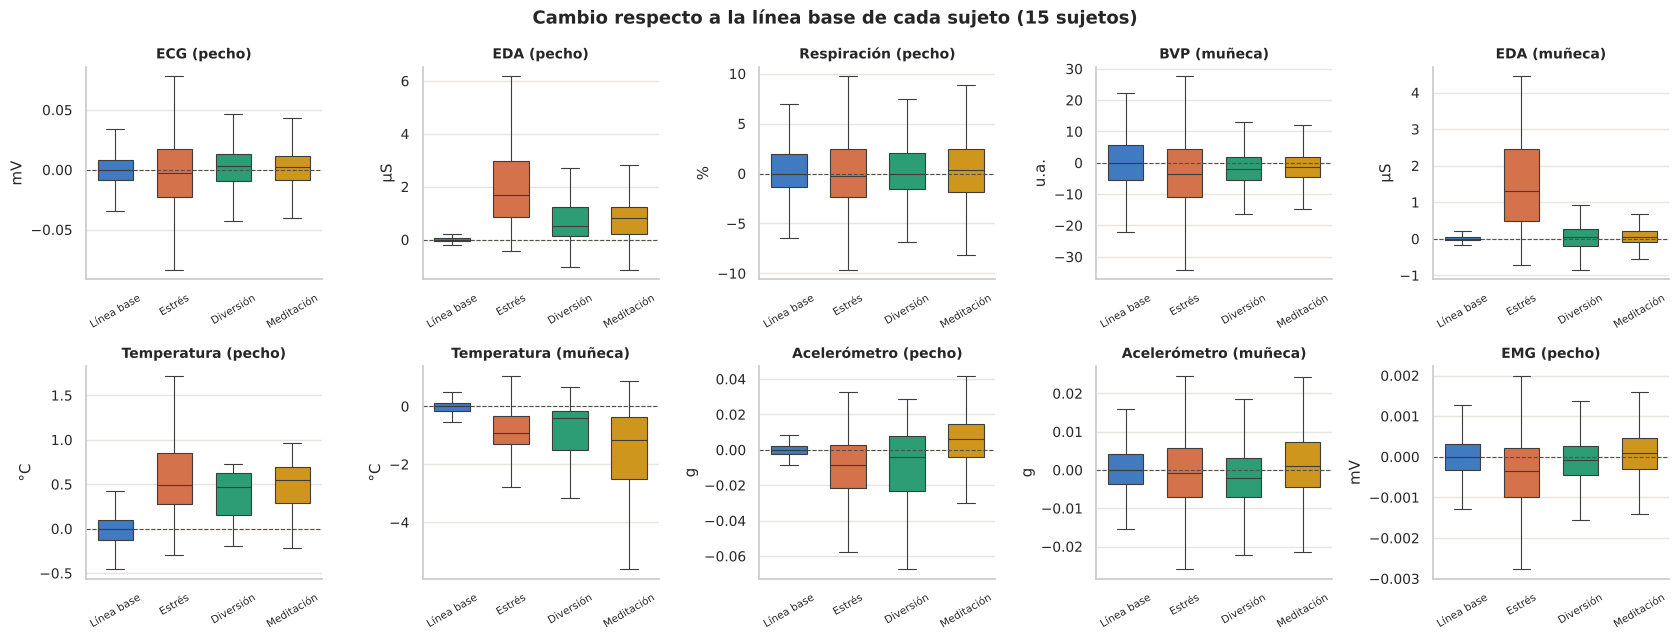

In [11]:
def dist_grid(col, title, fname):
    fig, axes = plt.subplots(2, 5, figsize=(17, 6.5))
    for ax, key in zip(axes.ravel(), cfg.ALL_SIGNALS):
        d = per_second[per_second.señal == key]
        sns.boxplot(data=d, x="condicion", y=col, order=cfg.COND_ORDER, ax=ax, showfliers=False,
                    palette=gr.COND_COLORS, hue="condicion", legend=False, width=0.6, linewidth=0.8)
        ax.set_title(cfg.SIGNALS[key]["name"]); ax.set_xlabel("")
        ax.set_ylabel(cfg.SIGNALS[key]["unit"])
        ax.set_xticks(range(4), [gr.COND_ES[c] for c in cfg.COND_ORDER], rotation=30, fontsize=7.5)
        if col == "delta": ax.axhline(0, color="#52514e", lw=0.8, ls="--")
    fig.suptitle(title, fontweight="bold"); fig.tight_layout(); gr.savefig(fig, fname); plt.show()

dist_grid("valor", "Valores por segundo de las 10 señales, por condición (15 sujetos, sin atípicos)", "01_distribucion_absoluta")
dist_grid("delta", "Cambio respecto a la línea base de cada sujeto (15 sujetos)", "01_distribucion_delta_base")

## 5. ¿Los participantes se sintieron estresados? (cuestionarios)
WESAD incluye cuestionarios aplicados después de cada condición. Usamos dos:
- **SAM** (Self-Assessment Manikin): valencia (1 = muy desagradable, 9 = muy agradable) y activación
  (1 = muy calmado, 9 = muy activado).
- **STAI-6** (ansiedad de estado, versión corta de 6 ítems, escala 1–4). Calculamos un puntaje de ansiedad de 6 a 24:
  los ítems positivos se invierten. Supuesto: los ítems 1, 4 y 6 son positivos ("tranquilo", "relajado",
  "contento"); el patrón de respuestas lo respalda (suben en línea base y bajan en estrés), pero
  **hay que confirmarlo en `wesad_readme.pdf`**.

Si el estrés se indujo bien, en la condición de estrés esperamos **menor valencia, mayor activación y mayor ansiedad**.
Esto valida que las etiquetas "stress" del dataset corresponden a una vivencia real de estrés.

In [12]:
q_rows = []
for sid in SUBJECTS:
    q = carga.read_quest(DATA_PATH, sid)
    if "DIM" in q:
        for _, r in q["DIM"].iterrows():
            q_rows.append(dict(sujeto=f"S{sid}", condicion=r.condicion, medida="Valencia (SAM)", valor=r.item_1))
            q_rows.append(dict(sujeto=f"S{sid}", condicion=r.condicion, medida="Activación (SAM)", valor=r.item_2))
    if "STAI" in q:
        st = q["STAI"]
        items = st[[f"item_{i}" for i in range(1, 7)]].values.astype(float)
        items[:, [0, 3, 5]] = 5 - items[:, [0, 3, 5]]       # invertir ítems positivos
        for cond, score in zip(st.condicion, items.sum(axis=1)):
            q_rows.append(dict(sujeto=f"S{sid}", condicion=cond, medida="Ansiedad STAI-6 (6-24)", valor=score))
quest = pd.DataFrame(q_rows)
quest["condicion"] = quest.condicion.replace({"meditation_1": "meditation", "meditation_2": "meditation"})
quest = quest.groupby(["sujeto", "condicion", "medida"], as_index=False).valor.mean()
quest.to_csv(os.path.join(cfg.OUT_DIRS["tables"], "autorreporte.csv"), index=False)
quest.pivot_table(index="medida", columns="condicion", values="valor", aggfunc="median")[cfg.COND_ORDER].round(1)

condicion,baseline,stress,amusement,meditation
medida,,,,
Activación (SAM),2.0,7.0,3.0,2.0
Ansiedad STAI-6 (6-24),10.0,19.0,9.0,10.0
Valencia (SAM),7.0,5.0,8.0,6.5


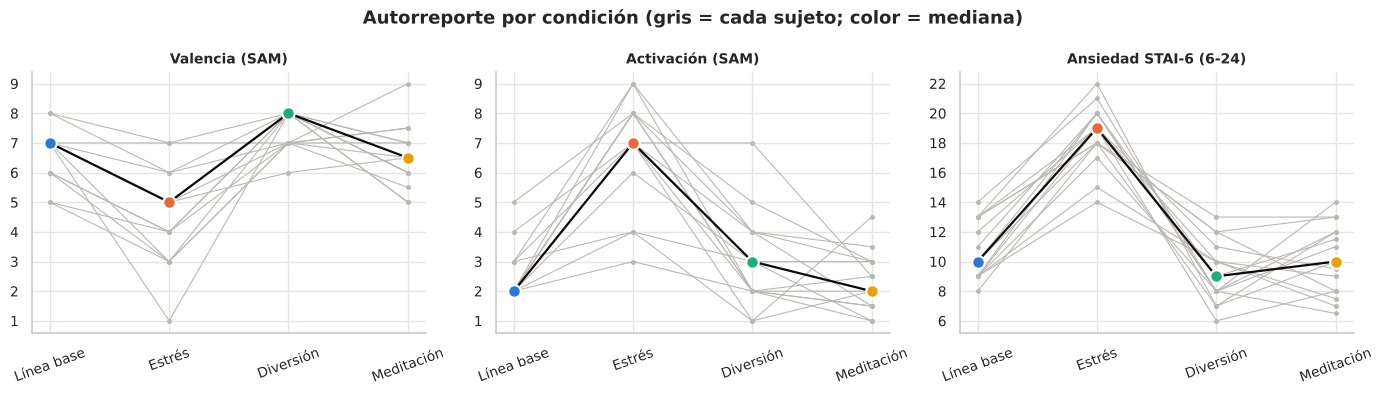

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, m in zip(axes, ["Valencia (SAM)", "Activación (SAM)", "Ansiedad STAI-6 (6-24)"]):
    d = quest[quest.medida == m].pivot(index="sujeto", columns="condicion", values="valor")[cfg.COND_ORDER]
    for _, r in d.iterrows():
        ax.plot(range(4), r.values, color="#b9b8b2", lw=0.8, marker="o", ms=2.5)
    med = d.median()
    ax.plot(range(4), med.values, color="#0b0b0b", lw=1.6)
    for i, c in enumerate(cfg.COND_ORDER):
        ax.plot(i, med[c], "o", ms=9, color=gr.COND_COLORS[c], mec="white", mew=1.5, zorder=3)
    ax.set_xticks(range(4), [gr.COND_ES[c] for c in cfg.COND_ORDER], rotation=20)
    ax.set_title(m)
fig.suptitle("Autorreporte por condición (gris = cada sujeto; color = mediana)", fontweight="bold")
fig.tight_layout(); gr.savefig(fig, "01_autorreporte"); plt.show()

**¿Quién NO reportó más ansiedad en estrés que en línea base?** Estos sujetos merecen atención en el
análisis de errores del modelo (cruzar con las notas del investigador de la sección 1).

In [14]:
stai = quest[quest.medida.str.startswith("Ansiedad")].pivot(index="sujeto", columns="condicion", values="valor")
stai["Δ estrés - base"] = stai["stress"] - stai["baseline"]
sin_resp = stai[stai["Δ estrés - base"] <= 0][["baseline", "stress", "Δ estrés - base"]]
sin_resp.join(notas_df.set_index("sujeto"))

,baseline,stress,Δ estrés - base,nota
sujeto,,,,


## 📌 Qué encontramos con los datos reales (15 sujetos)
- **Datos completos y sincronizados:** 0 valores faltantes y 0 s de desfase entre pecho, muñeca y etiquetas.
  No hace falta resincronizar con el doble toque.
- **Sesiones de 87 a 118 min.** Por sujeto hay ~20 min de línea base, ~11 de estrés, ~6 de diversión y ~13 de meditación.
- **Desbalance:** en la tarea de 3 clases, 53 % del tiempo es línea base, 30 % estrés y 17 % diversión.
- **Notas del investigador** para tener presentes: S2 y S17 (sensor de temperatura del pecho mal adherido),
  S6 y S15 (posiblemente poco estresados en el TSST), S5 (pudo dormirse en la meditación), S8 y S16 (frío en la
  sala del estrés), S3 (línea base al sol).
- **El estrés se indujo bien:** los 15 sujetos reportan más ansiedad (STAI-6) en estrés que en línea base
  (mediana 10 → 19) y más activación (SAM, mediana 2 → 7). Incluso S6 y S15, aunque sus notas dicen lo contrario.
- **En las distribuciones**, la EDA de muñeca y de pecho suben en estrés y la temperatura de muñeca baja.
  ECG, BVP, respiración y EMG oscilan alrededor de cero y su valor por segundo no dice nada: para ellas sirven los
  marcadores del notebook 04.

## Resumen de este notebook
- Inventario, bloques y autorreporte quedan guardados en `salidas/tablas/`; las figuras en `salidas/figuras/`.
- Siguiente paso: **02_control_de_calidad**, que busca muestras dañadas en las 10 señales.